<a href="https://colab.research.google.com/github/mowfka-gif/-data-mining-final-project/blob/main/Group_6_Advanced_Data_Mining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ĐỒ ÁN KHAI PHÁ DỮ LIỆU — CHƯƠNG 3 ĐẾN 6

Notebook tổng hợp từ ba notebook gốc. Các ô mã nguồn, nội dung và kết quả đã lưu được giữ nguyên. **Chạy trên Google Colab** và tải lên `bank-additional-full.csv` khi được yêu cầu. Một số ô tải tệp về máy có thể kích hoạt hộp thoại tải xuống.

---
# CHƯƠNG 3 VÀ 4

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving bank-additional-full.csv to bank-additional-full (1).csv


In [ ]:
import pandas as pd

# Đọc dữ liệu Bank Marketing
df = pd.read_csv("bank-additional-full.csv", sep=";")

# Kiểm tra kích thước
print("Kích thước dữ liệu:", df.shape)

# Hiển thị 5 dòng đầu tiên
print("\n5 dòng dữ liệu đầu tiên:")
display(df.head())

# Kiểm tra thông tin các biến
print("\nThông tin dữ liệu:")
df.info()

# Thống kê biến mục tiêu
print("\nPhân bố biến y:")
print(df["y"].value_counts())

Kích thước dữ liệu: (41188, 21)

5 dòng dữ liệu đầu tiên:


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no



Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.i

In [ ]:

import pandas as pd
from sklearn.model_selection import train_test_split

# Chia chỉ mục trên dữ liệu gốc, giữ nguyên thứ tự dòng
indices = df.index.to_numpy()

# 60% Train, 40% tạm thời
train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.4,
    stratify=df["y"],
    random_state=42
)

# Chia 40% còn lại thành 20% Validation, 20% Test
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.5,
    stratify=df.loc[temp_idx, "y"],
    random_state=42
)


# Luu chi muc dung chung cho cac chuong
split_indices = pd.DataFrame({
    "row_index": indices,
    "split": "test"
})

# Gan nhan cho tung tap
split_indices.loc[
    split_indices["row_index"].isin(train_idx),
    "split"
] = "train"

split_indices.loc[
    split_indices["row_index"].isin(val_idx),
    "split"
] = "validation"


split_indices.to_csv("split_indices.csv", index=False)

print(split_indices["split"].value_counts())
print(pd.crosstab(
    split_indices["split"],
    df["y"],
    normalize="index"
).round(4))


split
train         24712
test           8238
validation     8238
Name: count, dtype: int64
y               no     yes
split                     
test        0.8874  0.1126
train       0.8873  0.1127
validation  0.8874  0.1126


In [ ]:
# CHƯƠNG 3.2 - THỐNG KÊ MÔ TẢ DỮ LIỆU

# 1. Thống kê các biến số
print("THỐNG KÊ CÁC BIẾN ĐỊNH LƯỢNG")
display(df.describe().round(2))

# 2. Thống kê các biến phân loại
print("THỐNG KÊ CÁC BIẾN ĐỊNH TÍNH")
display(df.describe(include=["object"]))

# 3. Kiểm tra tỷ lệ đăng ký
print("TỶ LỆ ĐĂNG KÝ TIỀN GỬI (%)")
display(
    (df["y"].value_counts(normalize=True) * 100)
    .round(2)
)

THỐNG KÊ CÁC BIẾN ĐỊNH LƯỢNG


,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00
mean,40.02,258.29,2.57,962.48,0.17,0.08,93.58,-40.50,3.62,5167.04
std,10.42,259.28,2.77,186.91,0.49,1.57,0.58,4.63,1.73,72.25
min,17.00,0.00,1.00,0.00,0.00,-3.40,92.20,-50.80,0.63,4963.60
25%,32.00,102.00,1.00,999.00,0.00,-1.80,93.08,-42.70,1.34,5099.10
50%,38.00,180.00,2.00,999.00,0.00,1.10,93.75,-41.80,4.86,5191.00
75%,47.00,319.00,3.00,999.00,0.00,1.40,93.99,-36.40,4.96,5228.10
max,98.00,4918.00,56.00,999.00,7.00,1.40,94.77,-26.90,5.04,5228.10


THỐNG KÊ CÁC BIẾN ĐỊNH TÍNH


,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,y
count,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188
unique,12,4,8,3,3,3,2,10,5,3,2
top,admin.,married,university.degree,no,yes,no,cellular,may,thu,nonexistent,no
freq,10422,24928,12168,32588,21576,33950,26144,13769,8623,35563,36548


TỶ LỆ ĐĂNG KÝ TIỀN GỬI (%)


,proportion
y,
no,88.73
yes,11.27


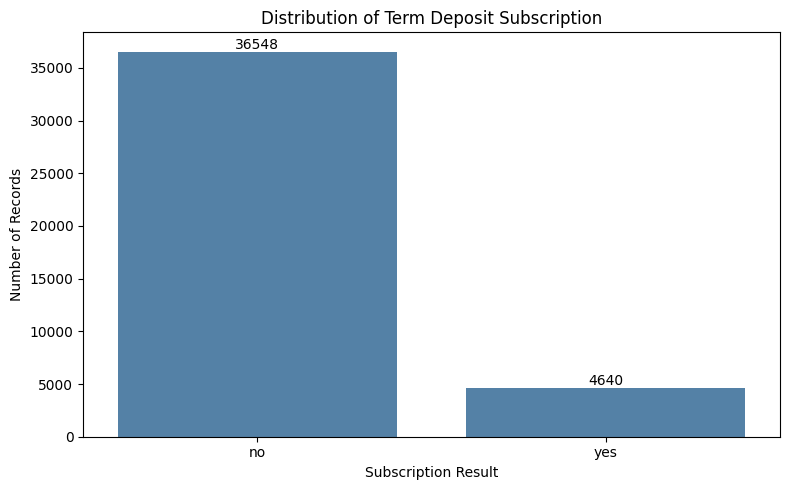

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Biểu đồ phân bố biến mục tiêu
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="y",
    order=["no", "yes"],
    color="steelblue"
)

# Hiển thị số lượng trên từng cột
for container in ax.containers:
    ax.bar_label(container)

plt.title("Distribution of Term Deposit Subscription")
plt.xlabel("Subscription Result")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.savefig("Figure_3_1_Subscription_Distribution.png", dpi=300, bbox_inches="tight")
plt.show()

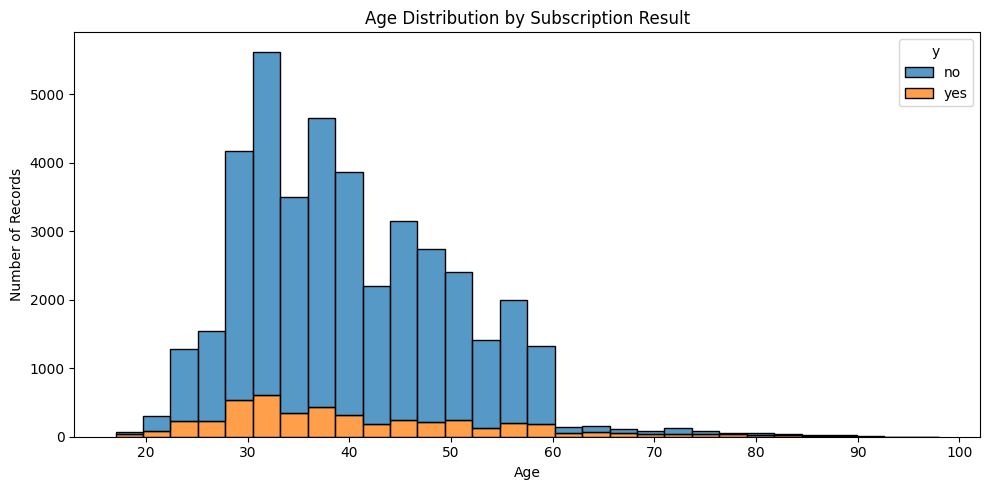

In [ ]:
# BIỂU ĐỒ 2 - PHÂN BỐ ĐỘ TUỔI THEO KẾT QUẢ ĐĂNG KÝ

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="age",
    hue="y",
    bins=30,
    multiple="stack"
)

plt.title("Age Distribution by Subscription Result")
plt.xlabel("Age")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.savefig("Figure_3_2_Age_Distribution.png", dpi=300)
plt.show()

TỶ LỆ ĐĂNG KÝ THEO NHÓM TUỔI


,age_group,total_contacts,total_yes,yes_rate
0,<30,5669,922,16.26
1,30-39,16938,1715,10.13
2,40-49,10526,834,7.92
3,50-59,6862,697,10.16
4,60+,1193,472,39.56


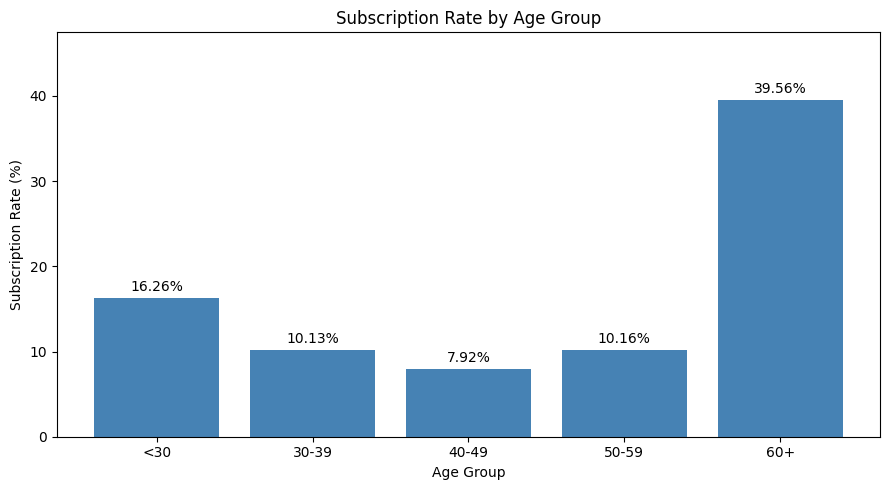

In [ ]:
# Tạo nhóm tuổi
import pandas as pd
import matplotlib.pyplot as plt

df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 29, 39, 49, 59, float("inf")],
    labels=["<30", "30-39", "40-49", "50-59", "60+"]
)

# Thống kê theo nhóm tuổi
age_summary = (
    df.groupby("age_group", observed=True)
      .agg(
          total_contacts=("y", "size"),
          total_yes=("y", lambda x: (x == "yes").sum())
      )
      .reset_index()
)

# Tính tỷ lệ đăng ký thành công
age_summary["yes_rate"] = (
    age_summary["total_yes"] /
    age_summary["total_contacts"] * 100
).round(2)

print("TỶ LỆ ĐĂNG KÝ THEO NHÓM TUỔI")
display(age_summary)

# Vẽ biểu đồ
plt.figure(figsize=(9, 5))

bars = plt.bar(
    age_summary["age_group"].astype(str),
    age_summary["yes_rate"],
    color="steelblue"
)

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.title("Subscription Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Subscription Rate (%)")

plt.ylim(0, age_summary["yes_rate"].max() * 1.2)
plt.tight_layout()

plt.savefig("Figure_3_3_Age_Group_Rate.png", dpi=300)
plt.show()

TỶ LỆ ĐĂNG KÝ THEO NGHỀ NGHIỆP


,job,total_contacts,total_yes,yes_rate
8,student,875,275,31.43
5,retired,1720,434,25.23
10,unemployed,1014,144,14.20
0,admin.,10422,1352,12.97
4,management,2924,328,11.22
11,unknown,330,37,11.21
9,technician,6743,730,10.83
6,self-employed,1421,149,10.49
3,housemaid,1060,106,10.00
2,entrepreneur,1456,124,8.52


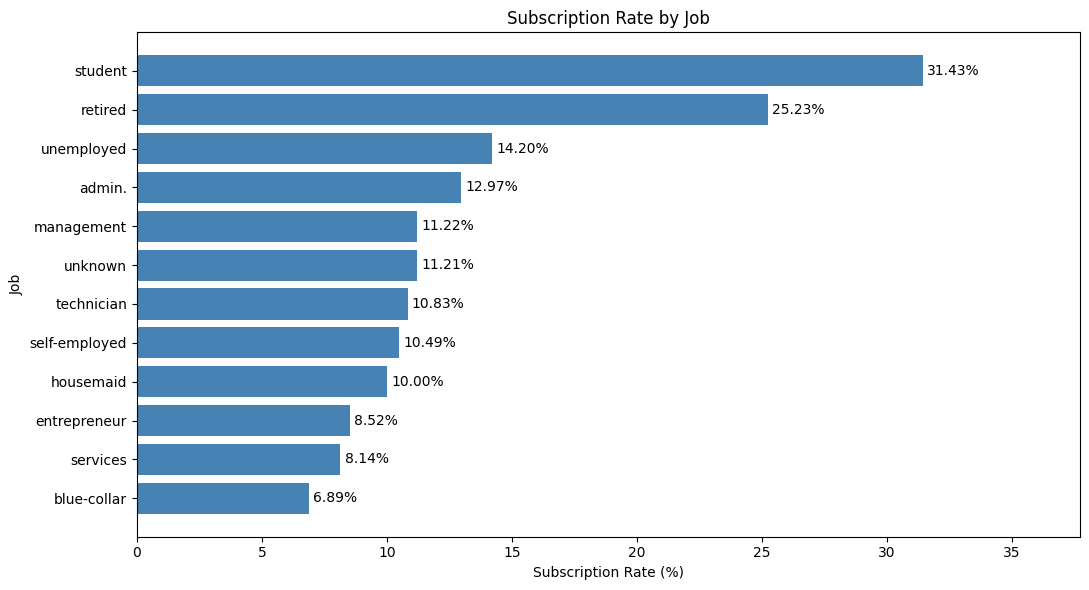

In [ ]:
# BIỂU ĐỒ 4 - TỶ LỆ ĐĂNG KÝ THEO NGHỀ NGHIỆP

import matplotlib.pyplot as plt

job_summary = (
    df.groupby("job")
      .agg(
          total_contacts=("y", "size"),
          total_yes=("y", lambda x: (x == "yes").sum())
      )
      .reset_index()
)

job_summary["yes_rate"] = (
    job_summary["total_yes"] /
    job_summary["total_contacts"] * 100
).round(2)

job_summary = job_summary.sort_values(
    "yes_rate", ascending=False
)

print("TỶ LỆ ĐĂNG KÝ THEO NGHỀ NGHIỆP")
display(job_summary)

plt.figure(figsize=(11, 6))

bars = plt.barh(
    job_summary["job"],
    job_summary["yes_rate"],
    color="steelblue"
)

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.gca().invert_yaxis()

plt.title("Subscription Rate by Job")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Job")

plt.xlim(0, job_summary["yes_rate"].max() * 1.2)
plt.tight_layout()

plt.savefig("Figure_3_4_Job_Rate.png", dpi=300)
plt.show()

BẢNG TỶ LỆ ĐĂNG KÝ THEO TUỔI VÀ NGHỀ NGHIỆP


,age_group,job,total_contacts,total_yes,yes_rate
0,<30,admin.,1622,294,18.13
1,<30,blue-collar,1164,94,8.08
2,<30,entrepreneur,103,7,6.80
3,<30,housemaid,45,5,11.11
4,<30,management,181,27,14.92
5,<30,retired,4,0,0.00
6,<30,self-employed,185,27,14.59
7,<30,services,721,81,11.23
8,<30,student,682,228,33.43
9,<30,technician,802,122,15.21


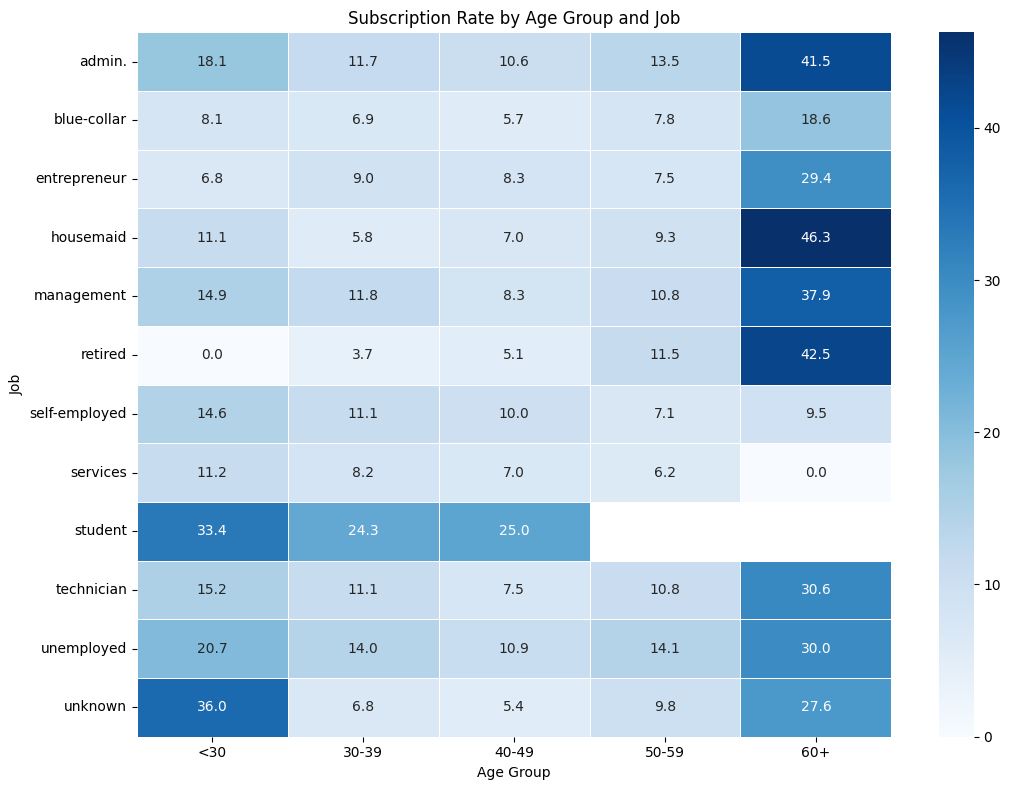

In [ ]:
# BIỂU ĐỒ 5 - TỶ LỆ ĐĂNG KÝ THEO NHÓM TUỔI VÀ NGHỀ NGHIỆP

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Tổng hợp theo nhóm tuổi và nghề nghiệp
age_job_summary = (
    df.groupby(["age_group", "job"], observed=True)
      .agg(
          total_contacts=("y", "size"),
          total_yes=("y", lambda x: (x == "yes").sum())
      )
      .reset_index()
)

# Tính tỷ lệ đăng ký
age_job_summary["yes_rate"] = (
    age_job_summary["total_yes"] /
    age_job_summary["total_contacts"] * 100
).round(2)

print("BẢNG TỶ LỆ ĐĂNG KÝ THEO TUỔI VÀ NGHỀ NGHIỆP")
display(age_job_summary)

# Tạo bảng ma trận
heatmap_data = age_job_summary.pivot(
    index="job",
    columns="age_group",
    values="yes_rate"
)

# Vẽ Heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Subscription Rate by Age Group and Job")
plt.xlabel("Age Group")
plt.ylabel("Job")

plt.tight_layout()

plt.savefig("Figure_3_5_Age_Job_Heatmap.png", dpi=300)
plt.show()

In [ ]:
# Lọc phân khúc có ít nhất 100 lượt liên hệ
segments = age_job_summary[
    age_job_summary["total_contacts"] >= 100
].copy()

# Sắp xếp theo tỷ lệ đăng ký
segments = segments.sort_values(
    "yes_rate", ascending=False
)

print("TOP 10 PHÂN KHÚC CÓ TỶ LỆ ĐĂNG KÝ CAO")
display(segments.head(10))

TOP 10 PHÂN KHÚC CÓ TỶ LỆ ĐĂNG KÝ CAO


,age_group,job,total_contacts,total_yes,yes_rate
52,60+,retired,785,334,42.55
47,60+,admin.,106,44,41.51
8,<30,student,682,228,33.43
20,30-39,student,185,45,24.32
10,<30,unemployed,135,28,20.74
0,<30,admin.,1622,294,18.13
9,<30,technician,802,122,15.21
4,<30,management,181,27,14.92
6,<30,self-employed,185,27,14.59
45,50-59,unemployed,170,24,14.12


TỶ LỆ ĐĂNG KÝ THEO KÊNH VÀ THÁNG


,month,contact,total_contacts,total_yes,yes_rate
10,mar,cellular,486,252,51.85
11,mar,telephone,60,24,40.00
0,apr,cellular,2445,493,20.16
1,apr,telephone,187,46,24.60
12,may,cellular,5518,614,11.13
13,may,telephone,8251,272,3.30
8,jun,cellular,820,349,42.56
9,jun,telephone,4498,210,4.67
6,jul,cellular,6096,591,9.69
7,jul,telephone,1078,58,5.38


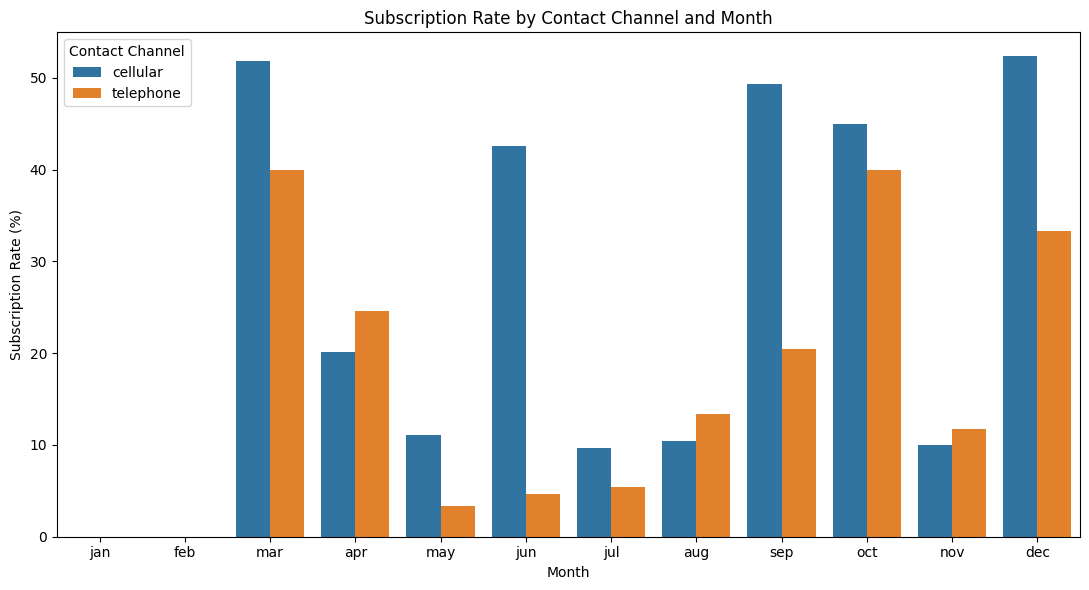

In [ ]:
# BIỂU ĐỒ 6 - TỶ LỆ ĐĂNG KÝ THEO KÊNH VÀ THÁNG

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

contact_month = (
    df.groupby(["month", "contact"])
      .agg(
          total_contacts=("y", "size"),
          total_yes=("y", lambda x: (x == "yes").sum())
      )
      .reset_index()
)

contact_month["yes_rate"] = (
    contact_month["total_yes"] /
    contact_month["total_contacts"] * 100
).round(2)

# Sắp xếp tháng theo thứ tự thời gian
month_order = [
    "jan", "feb", "mar", "apr", "may", "jun",
    "jul", "aug", "sep", "oct", "nov", "dec"
]

contact_month["month"] = pd.Categorical(
    contact_month["month"],
    categories=month_order,
    ordered=True
)

contact_month = contact_month.sort_values(
    ["month", "contact"]
)

print("TỶ LỆ ĐĂNG KÝ THEO KÊNH VÀ THÁNG")
display(contact_month)

# Vẽ biểu đồ
plt.figure(figsize=(11, 6))

sns.barplot(
    data=contact_month,
    x="month",
    y="yes_rate",
    hue="contact"
)

plt.title("Subscription Rate by Contact Channel and Month")
plt.xlabel("Month")
plt.ylabel("Subscription Rate (%)")
plt.legend(title="Contact Channel")

plt.tight_layout()
plt.savefig("Figure_3_6_Contact_Month.png", dpi=300)
plt.show()

In [ ]:
# Kiểm tra số lượt liên hệ và tỷ lệ đăng ký theo tháng, kênh
contact_month_check = contact_month[
    ["month", "contact", "total_contacts",
     "total_yes", "yes_rate"]
].copy()

print("BẢNG KIỂM TRA KÊNH LIÊN HỆ THEO THÁNG")
display(contact_month_check.to_string(index=False))

BẢNG KIỂM TRA KÊNH LIÊN HỆ THEO THÁNG


'month   contact  total_contacts  total_yes  yes_rate\n  mar  cellular             486        252     51.85\n  mar telephone              60         24     40.00\n  apr  cellular            2445        493     20.16\n  apr telephone             187         46     24.60\n  may  cellular            5518        614     11.13\n  may telephone            8251        272      3.30\n  jun  cellular             820        349     42.56\n  jun telephone            4498        210      4.67\n  jul  cellular            6096        591      9.69\n  jul telephone            1078         58      5.38\n  aug  cellular            5909        619     10.48\n  aug telephone             269         36     13.38\n  sep  cellular             482        238     49.38\n  sep telephone              88         18     20.45\n  oct  cellular             563        253     44.94\n  oct telephone             155         62     40.00\n  nov  cellular            3676        366      9.96\n  nov telephone            

KẾT QUẢ CHIẾN DỊCH TRƯỚC


,poutcome,total_contacts,total_yes,yes_rate
0,failure,4252,605,14.23
1,nonexistent,35563,3141,8.83
2,success,1373,894,65.11


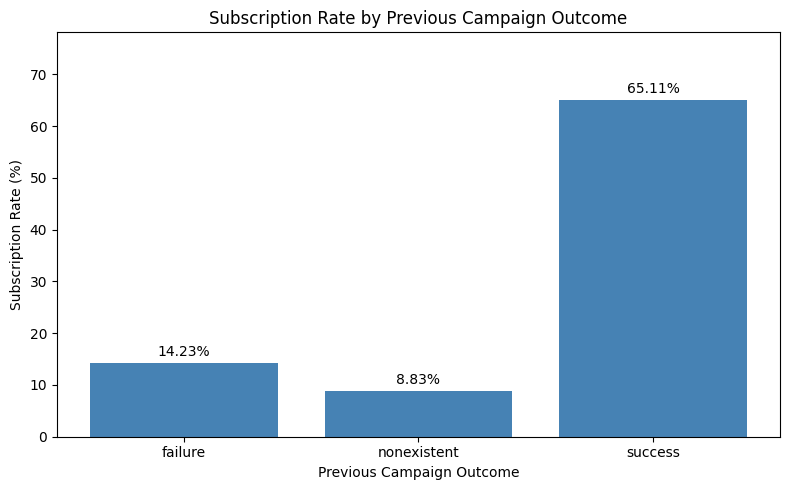

In [ ]:
# BIỂU ĐỒ 7 - TỶ LỆ ĐĂNG KÝ THEO KẾT QUẢ CHIẾN DỊCH TRƯỚC

import matplotlib.pyplot as plt

poutcome_summary = (
    df.groupby("poutcome")
      .agg(
          total_contacts=("y", "size"),
          total_yes=("y", lambda x: (x == "yes").sum())
      )
      .reset_index()
)

poutcome_summary["yes_rate"] = (
    poutcome_summary["total_yes"] /
    poutcome_summary["total_contacts"] * 100
).round(2)

print("KẾT QUẢ CHIẾN DỊCH TRƯỚC")
display(poutcome_summary)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    poutcome_summary["poutcome"],
    poutcome_summary["yes_rate"],
    color="steelblue"
)

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.title("Subscription Rate by Previous Campaign Outcome")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Subscription Rate (%)")

plt.ylim(0, poutcome_summary["yes_rate"].max() * 1.2)
plt.tight_layout()

plt.savefig("Figure_3_7_Poutcome.png", dpi=300)
plt.show()

TỶ LỆ ĐĂNG KÝ THEO SỐ LẦN LIÊN HỆ


,campaign_group,total_contacts,total_yes,yes_rate
0,1,17642,2300,13.04
1,2,10570,1211,11.46
2,3-5,9591,943,9.83
3,6-10,2516,159,6.32
4,>10,869,27,3.11


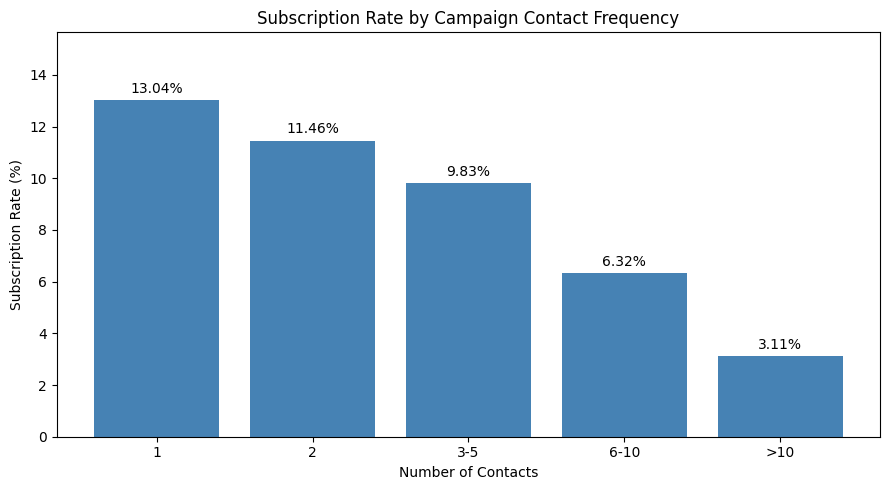

In [ ]:
# BIỂU ĐỒ 8 - TỶ LỆ ĐĂNG KÝ THEO SỐ LẦN LIÊN HỆ

import pandas as pd
import matplotlib.pyplot as plt

# Tạo nhóm số lần liên hệ
df["campaign_group"] = pd.cut(
    df["campaign"],
    bins=[0, 1, 2, 5, 10, float("inf")],
    labels=["1", "2", "3-5", "6-10", ">10"]
)

# Tổng hợp dữ liệu
campaign_summary = (
    df.groupby("campaign_group", observed=True)
      .agg(
          total_contacts=("y", "size"),
          total_yes=("y", lambda x: (x == "yes").sum())
      )
      .reset_index()
)

# Tính tỷ lệ đăng ký
campaign_summary["yes_rate"] = (
    campaign_summary["total_yes"] /
    campaign_summary["total_contacts"] * 100
).round(2)

print("TỶ LỆ ĐĂNG KÝ THEO SỐ LẦN LIÊN HỆ")
display(campaign_summary)

# Vẽ biểu đồ
plt.figure(figsize=(9, 5))

bars = plt.bar(
    campaign_summary["campaign_group"].astype(str),
    campaign_summary["yes_rate"],
    color="steelblue"
)

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.title("Subscription Rate by Campaign Contact Frequency")
plt.xlabel("Number of Contacts")
plt.ylabel("Subscription Rate (%)")

plt.ylim(0, campaign_summary["yes_rate"].max() * 1.2)
plt.tight_layout()

plt.savefig("Figure_3_8_Campaign_Rate.png", dpi=300)
plt.show()

In [ ]:
# CHƯƠNG 3.3 - KIỂM TRA CHẤT LƯỢNG DỮ LIỆU

# 1. Kiểm tra giá trị thiếu
print("1. GIÁ TRỊ NULL")
print("Tổng null:", df.isnull().sum().sum())
display(df.isnull().sum().to_frame("null_count"))

# 2. Kiểm tra giá trị unknown
print("\n2. GIÁ TRỊ UNKNOWN")
unknown_count = (
    df.select_dtypes(include=["object"])
      .eq("unknown")
      .sum()
)
display(unknown_count[unknown_count > 0]
        .to_frame("unknown_count"))

# 3. Kiểm tra bản ghi trùng lặp
print("\n3. DỮ LIỆU TRÙNG LẶP")
original_columns = [
    "age", "job", "marital", "education",
    "default", "housing", "loan", "contact",
    "month", "day_of_week", "duration",
    "campaign", "pdays", "previous",
    "poutcome", "emp.var.rate",
    "cons.price.idx", "cons.conf.idx",
    "euribor3m", "nr.employed", "y"
]

print(
    "Số dòng trùng hoàn toàn:",
    df.duplicated(subset=original_columns).sum()
)

# 4. Kiểm tra mã đặc biệt pdays = 999
print("\n4. GIÁ TRỊ PDAYS = 999")
print("Số bản ghi:", (df["pdays"] == 999).sum())

# 5. Kiểm tra kích thước dữ liệu
print("\n5. KÍCH THƯỚC HIỆN TẠI")
print("Số dòng:", len(df))
print("Số biến gốc:", len(original_columns))

1. GIÁ TRỊ NULL
Tổng null: 0


,null_count
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0



2. GIÁ TRỊ UNKNOWN


,unknown_count
job,330
marital,80
education,1731
default,8597
housing,990
loan,990



3. DỮ LIỆU TRÙNG LẶP
Số dòng trùng hoàn toàn: 12

4. GIÁ TRỊ PDAYS = 999
Số bản ghi: 39673

5. KÍCH THƯỚC HIỆN TẠI
Số dòng: 41188
Số biến gốc: 21


In [ ]:
# CHƯƠNG 3.3 - KIỂM TRA OUTLIER BẰNG IQR

import pandas as pd

numeric_cols = [
    "age", "duration", "campaign",
    "pdays", "previous",
    "emp.var.rate", "cons.price.idx",
    "cons.conf.idx", "euribor3m",
    "nr.employed"
]

results = []

for col in numeric_cols:

    # Không áp dụng IQR trực tiếp cho pdays
    # vì 999 là mã quy ước đặc biệt
    if col == "pdays":
        continue

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (
        (df[col] < lower) |
        (df[col] > upper)
    ).sum()

    results.append({
        "Variable": col,
        "Q1": Q1,
        "Q3": Q3,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": outliers,
        "Outlier Rate (%)": round(
            outliers / len(df) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(results)

print("BẢNG KIỂM TRA OUTLIER")
display(outlier_summary)

BẢNG KIỂM TRA OUTLIER


,Variable,Q1,Q3,Lower Bound,Upper Bound,Outlier Count,Outlier Rate (%)
0,age,32.000,47.000,9.5000,69.5000,469,1.14
1,duration,102.000,319.000,-223.5000,644.5000,2963,7.19
2,campaign,1.000,3.000,-2.0000,6.0000,2406,5.84
3,previous,0.000,0.000,0.0000,0.0000,5625,13.66
4,emp.var.rate,-1.800,1.400,-6.6000,6.2000,0,0.00
5,cons.price.idx,93.075,93.994,91.6965,95.3725,0,0.00
6,cons.conf.idx,-42.700,-36.400,-52.1500,-26.9500,447,1.09
7,euribor3m,1.344,4.961,-4.0815,10.3865,0,0.00
8,nr.employed,5099.100,5228.100,4905.6000,5421.6000,0,0.00


In [ ]:
# CHƯƠNG 3.3 - TIỀN XỬ LÝ DỮ LIỆU

# Sao chép dữ liệu gốc
original_cols = [
    "age", "job", "marital", "education",
    "default", "housing", "loan", "contact",
    "month", "day_of_week", "duration",
    "campaign", "pdays", "previous",
    "poutcome", "emp.var.rate",
    "cons.price.idx", "cons.conf.idx",
    "euribor3m", "nr.employed", "y"
]

df_clean = df[original_cols].copy()

# Loại duration để dự đoán trước cuộc gọi
df_clean = df_clean.drop(columns=["duration"])

# Thống kê trước và sau
summary = pd.DataFrame({
    "Giai đoạn": [
        "Dữ liệu ban đầu",
        "Sau tiền xử lý"
    ],
    "Số dòng": [
        len(df),
        len(df_clean)
    ],
    "Số feature đầu vào": [
        len(original_cols) - 1,
        len(df_clean.columns) - 1
    ]
})

print("BẢNG THỐNG KÊ TRƯỚC VÀ SAU TIỀN XỬ LÝ")
display(summary)

# Lưu dữ liệu đã xử lý
df_clean.to_csv(
    "bank_cleaned.csv",
    index=False
)

print("Đã tạo file bank_cleaned.csv")

BẢNG THỐNG KÊ TRƯỚC VÀ SAU TIỀN XỬ LÝ


,Giai đoạn,Số dòng,Số feature đầu vào
0,Dữ liệu ban đầu,41188,20
1,Sau tiền xử lý,41188,19


Đã tạo file bank_cleaned.csv


In [ ]:

# Tao du lieu sau tien xu ly cho Chuong III
df_clean = df.drop(columns=["duration"]).copy()

# Kiem tra
print("Kich thuoc df_clean:", df_clean.shape)
print("So bien dau vao:", df_clean.shape[1] - 1)


Kich thuoc df_clean: (41188, 20)
So bien dau vao: 19


In [ ]:
# CHƯƠNG 3.4 - ĐÁNH GIÁ FEATURE BẰNG MUTUAL INFORMATION

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OrdinalEncoder

# Dữ liệu sau tiền xử lý
X = df_clean.drop(columns=["y"])
y = (df_clean["y"] == "yes").astype(int)


# Su dung dung tap Train 60% da chia o buoc truoc
# Khong chia lai du lieu 80/20

X_train = X.loc[train_idx].copy()
y_train = y.loc[train_idx].copy()

print("So dong Train dung de tinh MI:", len(X_train))
print("So dac trung:", X_train.shape[1])
print("Phan bo nhan Train:")
print(y_train.value_counts())


# Tạo bản sao dữ liệu train
X_mi = X_train.copy()

# Mã hóa biến định tính trên tập train
categorical_cols = X_mi.select_dtypes(
    include=["object", "category"]
).columns.tolist()

encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X_mi[categorical_cols] = encoder.fit_transform(
    X_mi[categorical_cols]
)

# Tính Mutual Information
mi_scores = mutual_info_classif(
    X_mi,
    y_train,
    discrete_features=[
        col in categorical_cols
        for col in X_mi.columns
    ],
    random_state=42
)

mi_summary = pd.DataFrame({
    "Feature": X_mi.columns,
    "MI Score": mi_scores
}).sort_values(
    "MI Score",
    ascending=False
).reset_index(drop=True)

print("BẢNG ĐÁNH GIÁ FEATURE SELECTION")
display(mi_summary)

# Lưu bảng
mi_summary.to_csv(
    "Feature_Selection_MI.csv",
    index=False
)

So dong Train dung de tinh MI: 24712
So dac trung: 19
Phan bo nhan Train:
y
0    21928
1     2784
Name: count, dtype: int64
BẢNG ĐÁNH GIÁ FEATURE SELECTION


,Feature,MI Score
0,euribor3m,0.071151
1,cons.conf.idx,0.066765
2,nr.employed,0.062908
3,cons.price.idx,0.062836
4,emp.var.rate,0.054016
5,pdays,0.032698
6,poutcome,0.029855
7,month,0.025907
8,previous,0.018789
9,age,0.011628


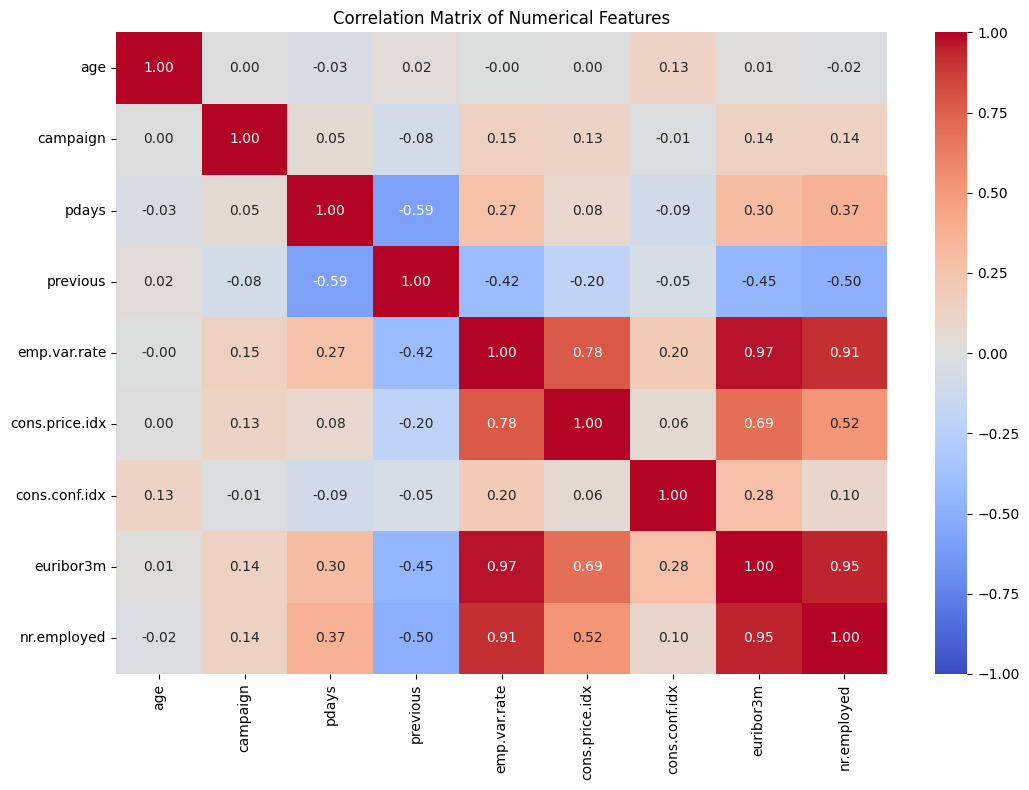

CÁC CẶP FEATURE CÓ TƯƠNG QUAN MẠNH


,Feature 1,Feature 2,Abs Correlation
28,emp.var.rate,euribor3m,0.972245
35,euribor3m,nr.employed,0.945154
29,emp.var.rate,nr.employed,0.906970


In [ ]:
# CHƯƠNG 3.4 - KIỂM TRA TƯƠNG QUAN FEATURE

import matplotlib.pyplot as plt
import seaborn as sns

numeric_features = [
    "age", "campaign", "pdays", "previous",
    "emp.var.rate", "cons.price.idx",
    "cons.conf.idx", "euribor3m",
    "nr.employed"
]

corr_matrix = df_clean[numeric_features].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()

plt.savefig(
    "Figure_3_9_Feature_Correlation.png",
    dpi=300
)

plt.show()

# Liệt kê các cặp có tương quan mạnh
import numpy as np

upper = corr_matrix.abs().where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr = upper.stack().reset_index()
high_corr.columns = ["Feature 1", "Feature 2", "Abs Correlation"]

high_corr = high_corr[
    high_corr["Abs Correlation"] >= 0.8
].sort_values("Abs Correlation", ascending=False)

print("CÁC CẶP FEATURE CÓ TƯƠNG QUAN MẠNH")
display(high_corr)

In [ ]:
# CHƯƠNG 3.4 - KIỂM THỬ FEATURE SELECTION

import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score, recall_score,
    f1_score, average_precision_score
)

# Danh sách feature đề xuất loại
drop_features = [
    "loan", "housing", "day_of_week",
    "emp.var.rate", "nr.employed"
]

# Hai phương án so sánh
X_full = df_clean.drop(columns=["y"])
X_selected = X_full.drop(columns=drop_features)
y = (df_clean["y"] == "yes").astype(int)


# Su dung chung chi muc 60/20/20 voi Chuong V
X_train = X_full.loc[train_idx].copy()
X_val = X_full.loc[val_idx].copy()
X_test = X_full.loc[test_idx].copy()

y_train = y.loc[train_idx].copy()
y_val = y.loc[val_idx].copy()
y_test = y.loc[test_idx].copy()

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


def evaluate_features(features, name):

    cat_cols = X_train[features].select_dtypes(
        include=["object", "category"]
    ).columns.tolist()

    num_cols = [c for c in features if c not in cat_cols]

    preprocessor = ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ])

    model = Pipeline([
        ("preprocess", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        ))
    ])

    model.fit(X_train[features], y_train)

    predictions = model.predict(X_val[features])
    probabilities = model.predict_proba(X_val[features])[:, 1]

    return {
        "Phương án": name,
        "Số feature gốc": len(features),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "PR-AUC": average_precision_score(
            y_val, probabilities
        )
    }


# So sanh 3 phuong an: 19 - 17 - 14 bien
features_17 = [
    col for col in X_full.columns
    if col not in ["housing", "loan"]
]

results = pd.DataFrame([
    evaluate_features(
        X_full.columns.tolist(), "19 features"
    ),
    evaluate_features(
        features_17, "17 features"
    ),
    evaluate_features(
        X_selected.columns.tolist(), "14 features"
    )
])


print("SO SÁNH HIỆU QUẢ FEATURE SELECTION")
display(results.round(4))

results.to_csv(
    "Feature_Selection_Comparison.csv",
    index=False
)

Train: (24712, 19)
Validation: (8238, 19)
Test: (8238, 19)
SO SÁNH HIỆU QUẢ FEATURE SELECTION


,Phương án,Số feature gốc,Precision,Recall,F1,PR-AUC
0,19 features,19,0.3611,0.6487,0.4640,0.4664
1,17 features,17,0.3629,0.6476,0.4652,0.4662
2,14 features,14,0.3514,0.6498,0.4561,0.4558


In [ ]:
# CHƯƠNG 3.5 - XUẤT DỮ LIỆU SAU FEATURE SELECTION

# Tạo tập dữ liệu 17 feature + nhãn y
selected_features = [
    col for col in df_clean.columns
    if col not in ["housing", "loan", "y"]
]

df_final = df_clean[selected_features + ["y"]].copy()

print("Số dòng:", df_final.shape[0])
print("Số feature đầu vào:", len(selected_features))
print("Tổng số cột:", df_final.shape[1])

# Lưu file cho nhóm
df_final.to_csv(
    "bank_selected_17_features.csv",
    index=False
)

print("Đã tạo file bank_selected_17_features.csv")

Số dòng: 41188
Số feature đầu vào: 17
Tổng số cột: 18
Đã tạo file bank_selected_17_features.csv


In [ ]:
# CHƯƠNG 4.1 - CHUẨN BỊ DỮ LIỆU DATA WAREHOUSE

import pandas as pd

df_dw = df_clean.copy()

required_columns = [
    "age", "job", "contact", "month",
    "poutcome", "campaign", "y"
]

# Kiểm tra các cột phục vụ Business Queries
print("CÁC BIẾN DÙNG CHO DATA WAREHOUSE")
print(df_dw[required_columns].info())

print("\nKÍCH THƯỚC DỮ LIỆU")
print("Số bản ghi:", len(df_dw))
print("Số cột:", df_dw.shape[1])

print("\nKIỂM TRA NHÃN Y")
print(df_dw["y"].value_counts())

CÁC BIẾN DÙNG CHO DATA WAREHOUSE
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   age       41188 non-null  int64 
 1   job       41188 non-null  object
 2   contact   41188 non-null  object
 3   month     41188 non-null  object
 4   poutcome  41188 non-null  object
 5   campaign  41188 non-null  int64 
 6   y         41188 non-null  object
dtypes: int64(2), object(5)
memory usage: 2.2+ MB
None

KÍCH THƯỚC DỮ LIỆU
Số bản ghi: 41188
Số cột: 20

KIỂM TRA NHÃN Y
y
no     36548
yes     4640
Name: count, dtype: int64


In [ ]:
# CHƯƠNG 4.2 - TẠO DIMENSION TABLES

import pandas as pd

dw = df_clean.copy()

# Tạo nhóm tuổi
dw["age_group"] = pd.cut(
    dw["age"],
    bins=[0, 29, 39, 49, 59, float("inf")],
    labels=["<30", "30-39", "40-49", "50-59", "60+"]
).astype(str)

# Tạo nhóm số lần liên hệ
dw["campaign_group"] = pd.cut(
    dw["campaign"],
    bins=[0, 1, 2, 5, 10, float("inf")],
    labels=["1", "2", "3-5", "6-10", ">10"]
).astype(str)

# Hàm tạo dimension và khóa chính
def make_dimension(data, cols, key):
    dim = data[cols].drop_duplicates().reset_index(drop=True)
    dim.insert(0, key, range(1, len(dim) + 1))
    return dim

dim_customer = make_dimension(
    dw, ["age_group", "job"], "customer_key"
)

dim_channel = make_dimension(
    dw, ["contact"], "channel_key"
)

dim_time = make_dimension(
    dw, ["month"], "time_key"
)

dim_previous = make_dimension(
    dw, ["poutcome"], "previous_key"
)

dim_campaign = make_dimension(
    dw, ["campaign_group"], "campaign_key"
)

dimensions = {
    "Dim_Customer": dim_customer,
    "Dim_Channel": dim_channel,
    "Dim_Time": dim_time,
    "Dim_Previous": dim_previous,
    "Dim_Campaign": dim_campaign
}

print("KẾT QUẢ TẠO DIMENSION TABLES")

for name, table in dimensions.items():
    print(f"{name}: {len(table)} dòng")
    display(table.head())

KẾT QUẢ TẠO DIMENSION TABLES
Dim_Customer: 58 dòng


,customer_key,age_group,job
0,1,50-59,housemaid
1,2,50-59,services
2,3,30-39,services
3,4,40-49,admin.
4,5,40-49,services


Dim_Channel: 2 dòng


,channel_key,contact
0,1,telephone
1,2,cellular


Dim_Time: 10 dòng


,time_key,month
0,1,may
1,2,jun
2,3,jul
3,4,aug
4,5,oct


Dim_Previous: 3 dòng


,previous_key,poutcome
0,1,nonexistent
1,2,failure
2,3,success


Dim_Campaign: 5 dòng


,campaign_key,campaign_group
0,1,1
1,2,2
2,3,3-5
3,4,6-10
4,5,>10


In [ ]:
# CHƯƠNG 4.3 - TẠO FACT_CAMPAIGN

# Tạo bản sao dữ liệu
fact = dw.copy()

# Ghép khóa ngoại từ các bảng Dimension
fact = fact.merge(
    dim_customer,
    on=["age_group", "job"],
    how="left",
    validate="many_to_one"
)

fact = fact.merge(
    dim_channel,
    on="contact",
    how="left",
    validate="many_to_one"
)

fact = fact.merge(
    dim_time,
    on="month",
    how="left",
    validate="many_to_one"
)

fact = fact.merge(
    dim_previous,
    on="poutcome",
    how="left",
    validate="many_to_one"
)

fact = fact.merge(
    dim_campaign,
    on="campaign_group",
    how="left",
    validate="many_to_one"
)

# Tạo các measure
fact["total_contacts"] = 1
fact["total_yes"] = (fact["y"] == "yes").astype(int)

# Tạo khóa chính
fact["contact_id"] = range(1, len(fact) + 1)

# Chỉ giữ các cột cần thiết
fact_campaign = fact[[
    "contact_id",
    "customer_key",
    "channel_key",
    "time_key",
    "previous_key",
    "campaign_key",
    "total_contacts",
    "total_yes"
]].copy()

# Kiểm tra dữ liệu
foreign_keys = [
    "customer_key",
    "channel_key",
    "time_key",
    "previous_key",
    "campaign_key"
]

assert len(fact_campaign) == len(dw)
assert fact_campaign["contact_id"].is_unique
assert fact_campaign[foreign_keys].notna().all().all()

print("KẾT QUẢ TẠO FACT_CAMPAIGN")
print("Số dòng:", len(fact_campaign))
print("Số cột:", fact_campaign.shape[1])

print("\nTỔNG HỢP MEASURE")
print("Tổng liên hệ:", fact_campaign["total_contacts"].sum())
print("Tổng đăng ký thành công:", fact_campaign["total_yes"].sum())

print("\n5 DÒNG ĐẦU TIÊN")
display(fact_campaign.head())

KẾT QUẢ TẠO FACT_CAMPAIGN
Số dòng: 41188
Số cột: 8

TỔNG HỢP MEASURE
Tổng liên hệ: 41188
Tổng đăng ký thành công: 4640

5 DÒNG ĐẦU TIÊN


,contact_id,customer_key,channel_key,time_key,previous_key,campaign_key,total_contacts,total_yes
0,1,1,1,1,1,1,1,0
1,2,2,1,1,1,1,1,0
2,3,3,1,1,1,1,1,0
3,4,4,1,1,1,1,1,0
4,5,2,1,1,1,1,1,0


In [ ]:
# CHƯƠNG 4.3 - TẠO DATA WAREHOUSE SQLITE HOÀN CHỈNH

import sqlite3
import pandas as pd

# 1. Đóng kết nối cũ nếu còn
try:
    conn.close()
except (NameError, sqlite3.Error):
    pass

# 2. Tạo lại database từ đầu
conn = sqlite3.connect("Bank_Marketing_DW.db")

# Tạm tắt kiểm tra khóa ngoại để xóa bảng cũ
conn.execute("PRAGMA foreign_keys = OFF")

conn.execute("DROP TABLE IF EXISTS Fact_Campaign")

for name in [
    "Dim_Customer",
    "Dim_Channel",
    "Dim_Time",
    "Dim_Previous",
    "Dim_Campaign"
]:
    conn.execute(f"DROP TABLE IF EXISTS {name}")

conn.commit()

# 3. Tạo 5 bảng Dimension có PRIMARY KEY
dimension_definitions = {
    "Dim_Customer": """
        CREATE TABLE Dim_Customer (
            customer_key INTEGER PRIMARY KEY,
            age_group TEXT,
            job TEXT
        )
    """,

    "Dim_Channel": """
        CREATE TABLE Dim_Channel (
            channel_key INTEGER PRIMARY KEY,
            contact TEXT
        )
    """,

    "Dim_Time": """
        CREATE TABLE Dim_Time (
            time_key INTEGER PRIMARY KEY,
            month TEXT
        )
    """,

    "Dim_Previous": """
        CREATE TABLE Dim_Previous (
            previous_key INTEGER PRIMARY KEY,
            poutcome TEXT
        )
    """,

    "Dim_Campaign": """
        CREATE TABLE Dim_Campaign (
            campaign_key INTEGER PRIMARY KEY,
            campaign_group TEXT
        )
    """
}

for sql in dimension_definitions.values():
    conn.execute(sql)

# 4. Nạp dữ liệu vào Dimension
dimension_data = {
    "Dim_Customer": dim_customer,
    "Dim_Channel": dim_channel,
    "Dim_Time": dim_time,
    "Dim_Previous": dim_previous,
    "Dim_Campaign": dim_campaign
}

for name, data in dimension_data.items():
    data.to_sql(
        name,
        conn,
        if_exists="append",
        index=False
    )

# 5. Tạo bảng Fact có khóa chính và khóa ngoại
conn.execute("""
CREATE TABLE Fact_Campaign (
    contact_id INTEGER PRIMARY KEY,
    customer_key INTEGER NOT NULL,
    channel_key INTEGER NOT NULL,
    time_key INTEGER NOT NULL,
    previous_key INTEGER NOT NULL,
    campaign_key INTEGER NOT NULL,
    total_contacts INTEGER NOT NULL,
    total_yes INTEGER NOT NULL,

    FOREIGN KEY (customer_key)
        REFERENCES Dim_Customer(customer_key),

    FOREIGN KEY (channel_key)
        REFERENCES Dim_Channel(channel_key),

    FOREIGN KEY (time_key)
        REFERENCES Dim_Time(time_key),

    FOREIGN KEY (previous_key)
        REFERENCES Dim_Previous(previous_key),

    FOREIGN KEY (campaign_key)
        REFERENCES Dim_Campaign(campaign_key)
)
""")

# 6. Bật kiểm tra khóa ngoại
conn.commit()
conn.execute("PRAGMA foreign_keys = ON")

# 7. Nạp dữ liệu Fact
fact_campaign.to_sql(
    "Fact_Campaign",
    conn,
    if_exists="append",
    index=False
)

conn.commit()

# 8. Kiểm tra số lượng bảng
print("DANH SÁCH BẢNG DATA WAREHOUSE")

tables_check = pd.read_sql_query("""
SELECT name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name
""", conn)

display(tables_check)

# 9. Kiểm tra kết quả
print("\nKIỂM TRA DỮ LIỆU FACT")

result = pd.read_sql_query("""
SELECT
    COUNT(*) AS total_records,
    SUM(total_contacts) AS total_contacts,
    SUM(total_yes) AS total_yes,
    ROUND(
        100.0 * SUM(total_yes) /
        NULLIF(SUM(total_contacts), 0),
        2
    ) AS subscription_rate
FROM Fact_Campaign
""", conn)

display(result)

# 10. Kiểm tra khóa ngoại
fk_errors = pd.read_sql_query(
    "PRAGMA foreign_key_check",
    conn
)

print("\nSố lỗi khóa ngoại:", len(fk_errors))

# 11. Kiểm tra khóa chính của các bảng
print("\nKIỂM TRA PRIMARY KEY")

for name in list(dimension_data.keys()) + ["Fact_Campaign"]:
    schema = pd.read_sql_query(
        f"PRAGMA table_info({name})", conn
    )
    pk = schema.loc[schema["pk"] > 0, "name"].tolist()
    print(f"{name}: {pk}")

print("\nHOÀN THÀNH TẠO DATA WAREHOUSE!")

DANH SÁCH BẢNG DATA WAREHOUSE


,name
0,Dim_Campaign
1,Dim_Channel
2,Dim_Customer
3,Dim_Previous
4,Dim_Time
5,Fact_Campaign



KIỂM TRA DỮ LIỆU FACT


,total_records,total_contacts,total_yes,subscription_rate
0,41188,41188,4640,11.27



Số lỗi khóa ngoại: 0

KIỂM TRA PRIMARY KEY
Dim_Customer: ['customer_key']
Dim_Channel: ['channel_key']
Dim_Time: ['time_key']
Dim_Previous: ['previous_key']
Dim_Campaign: ['campaign_key']
Fact_Campaign: ['contact_id']

HOÀN THÀNH TẠO DATA WAREHOUSE!


In [ ]:
# CHƯƠNG 4.4 - DATA CUBE BQ1
# TỶ LỆ ĐĂNG KÝ THEO NHÓM TUỔI VÀ NGHỀ NGHIỆP

query_bq1 = """
SELECT
    c.age_group,
    c.job,
    SUM(f.total_contacts) AS total_contacts,
    SUM(f.total_yes) AS total_yes,
    ROUND(
        100.0 * SUM(f.total_yes) /
        NULLIF(SUM(f.total_contacts), 0),
        2
    ) AS yes_rate
FROM Fact_Campaign f
JOIN Dim_Customer c
    ON f.customer_key = c.customer_key
GROUP BY
    c.age_group,
    c.job
ORDER BY
    yes_rate DESC
"""

cube_bq1 = pd.read_sql_query(query_bq1, conn)

print("DATA CUBE BQ1: NHÓM TUỔI × NGHỀ NGHIỆP")
display(cube_bq1.head(15))

print("\nSố phân khúc:", len(cube_bq1))
print("Tổng lượt liên hệ:", cube_bq1["total_contacts"].sum())
print("Tổng đăng ký:", cube_bq1["total_yes"].sum())

cube_bq1.to_csv("DataCube_BQ1.csv", index=False)

DATA CUBE BQ1: NHÓM TUỔI × NGHỀ NGHIỆP


,age_group,job,total_contacts,total_yes,yes_rate
0,60+,housemaid,67,31,46.27
1,60+,retired,785,334,42.55
2,60+,admin.,106,44,41.51
3,60+,management,58,22,37.93
4,<30,unknown,25,9,36.00
5,<30,student,682,228,33.43
6,60+,technician,49,15,30.61
7,60+,unemployed,10,3,30.00
8,60+,entrepreneur,17,5,29.41
9,60+,unknown,29,8,27.59



Số phân khúc: 58
Tổng lượt liên hệ: 41188
Tổng đăng ký: 4640


In [ ]:
# CHƯƠNG 4.4 - DATA CUBE BQ2
# TỶ LỆ ĐĂNG KÝ THEO KÊNH LIÊN HỆ VÀ THÁNG

query_bq2 = """
SELECT
    t.month,
    ch.contact,
    SUM(f.total_contacts) AS total_contacts,
    SUM(f.total_yes) AS total_yes,
    ROUND(
        100.0 * SUM(f.total_yes) /
        NULLIF(SUM(f.total_contacts), 0),
        2
    ) AS yes_rate
FROM Fact_Campaign f
JOIN Dim_Time t
    ON f.time_key = t.time_key
JOIN Dim_Channel ch
    ON f.channel_key = ch.channel_key
GROUP BY
    t.month,
    ch.contact
ORDER BY
    CASE t.month
        WHEN 'jan' THEN 1
        WHEN 'feb' THEN 2
        WHEN 'mar' THEN 3
        WHEN 'apr' THEN 4
        WHEN 'may' THEN 5
        WHEN 'jun' THEN 6
        WHEN 'jul' THEN 7
        WHEN 'aug' THEN 8
        WHEN 'sep' THEN 9
        WHEN 'oct' THEN 10
        WHEN 'nov' THEN 11
        WHEN 'dec' THEN 12
    END,
    ch.contact
"""

cube_bq2 = pd.read_sql_query(query_bq2, conn)

print("DATA CUBE BQ2: KÊNH LIÊN HỆ × THÁNG")
display(cube_bq2)

print("\nSố phân khúc:", len(cube_bq2))
print("Tổng lượt liên hệ:", cube_bq2["total_contacts"].sum())
print("Tổng đăng ký:", cube_bq2["total_yes"].sum())

cube_bq2.to_csv("DataCube_BQ2.csv", index=False)

print("\nĐã tạo file DataCube_BQ2.csv")

DATA CUBE BQ2: KÊNH LIÊN HỆ × THÁNG


,month,contact,total_contacts,total_yes,yes_rate
0,mar,cellular,486,252,51.85
1,mar,telephone,60,24,40.00
2,apr,cellular,2445,493,20.16
3,apr,telephone,187,46,24.60
4,may,cellular,5518,614,11.13
5,may,telephone,8251,272,3.30
6,jun,cellular,820,349,42.56
7,jun,telephone,4498,210,4.67
8,jul,cellular,6096,591,9.69
9,jul,telephone,1078,58,5.38



Số phân khúc: 20
Tổng lượt liên hệ: 41188
Tổng đăng ký: 4640

Đã tạo file DataCube_BQ2.csv


In [ ]:
import glob
import zipfile
from google.colab import files

image_files = glob.glob("/content/Figure_*.png")

with zipfile.ZipFile("/content/Tat_ca_hinh_Chuong_3_4.zip", "w") as zipf:
    for file in image_files:
        zipf.write(file, arcname=file.split("/")[-1])

print(f"Đã đóng gói {len(image_files)} hình ảnh.")

files.download("/content/Tat_ca_hinh_Chuong_3_4.zip")

Đã đóng gói 9 hình ảnh.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# CHƯƠNG 4.4 - DATA CUBE BQ3
# PHÂN TÍCH KẾT QUẢ CHIẾN DỊCH TRƯỚC

query_bq3 = """
SELECT
    p.poutcome,
    SUM(f.total_contacts) AS total_contacts,
    SUM(f.total_yes) AS total_yes,
    ROUND(
        100.0 * SUM(f.total_yes) /
        NULLIF(SUM(f.total_contacts), 0),
        2
    ) AS yes_rate
FROM Fact_Campaign f
JOIN Dim_Previous p
    ON f.previous_key = p.previous_key
GROUP BY
    p.poutcome
ORDER BY
    yes_rate DESC
"""

cube_bq3 = pd.read_sql_query(query_bq3, conn)

print("DATA CUBE BQ3: KẾT QUẢ CHIẾN DỊCH TRƯỚC")
display(cube_bq3)

print("\nSố nhóm:", len(cube_bq3))
print("Tổng lượt liên hệ:", cube_bq3["total_contacts"].sum())
print("Tổng đăng ký:", cube_bq3["total_yes"].sum())

cube_bq3.to_csv("DataCube_BQ3.csv", index=False)

print("\nĐã tạo file DataCube_BQ3.csv")

DATA CUBE BQ3: KẾT QUẢ CHIẾN DỊCH TRƯỚC


,poutcome,total_contacts,total_yes,yes_rate
0,success,1373,894,65.11
1,failure,4252,605,14.23
2,nonexistent,35563,3141,8.83



Số nhóm: 3
Tổng lượt liên hệ: 41188
Tổng đăng ký: 4640

Đã tạo file DataCube_BQ3.csv


In [ ]:
# CHƯƠNG 4.4 - DATA CUBE BQ4
# PHÂN TÍCH THEO SỐ LẦN LIÊN HỆ

query_bq4 = """
SELECT
    c.campaign_group,
    SUM(f.total_contacts) AS total_contacts,
    SUM(f.total_yes) AS total_yes,
    ROUND(
        100.0 * SUM(f.total_yes) /
        NULLIF(SUM(f.total_contacts), 0),
        2
    ) AS yes_rate
FROM Fact_Campaign f
JOIN Dim_Campaign c
    ON f.campaign_key = c.campaign_key
GROUP BY
    c.campaign_group
ORDER BY
    CASE c.campaign_group
        WHEN '1' THEN 1
        WHEN '2' THEN 2
        WHEN '3-5' THEN 3
        WHEN '6-10' THEN 4
        WHEN '>10' THEN 5
    END
"""

cube_bq4 = pd.read_sql_query(query_bq4, conn)

print("DATA CUBE BQ4: SỐ LẦN LIÊN HỆ")
display(cube_bq4)

print("\nSố nhóm:", len(cube_bq4))
print("Tổng lượt liên hệ:",
      cube_bq4["total_contacts"].sum())
print("Tổng đăng ký:",
      cube_bq4["total_yes"].sum())

cube_bq4.to_csv("DataCube_BQ4.csv", index=False)

print("\nĐã tạo file DataCube_BQ4.csv")

DATA CUBE BQ4: SỐ LẦN LIÊN HỆ


,campaign_group,total_contacts,total_yes,yes_rate
0,1,17642,2300,13.04
1,2,10570,1211,11.46
2,3-5,9591,943,9.83
3,6-10,2516,159,6.32
4,>10,869,27,3.11



Số nhóm: 5
Tổng lượt liên hệ: 41188
Tổng đăng ký: 4640

Đã tạo file DataCube_BQ4.csv


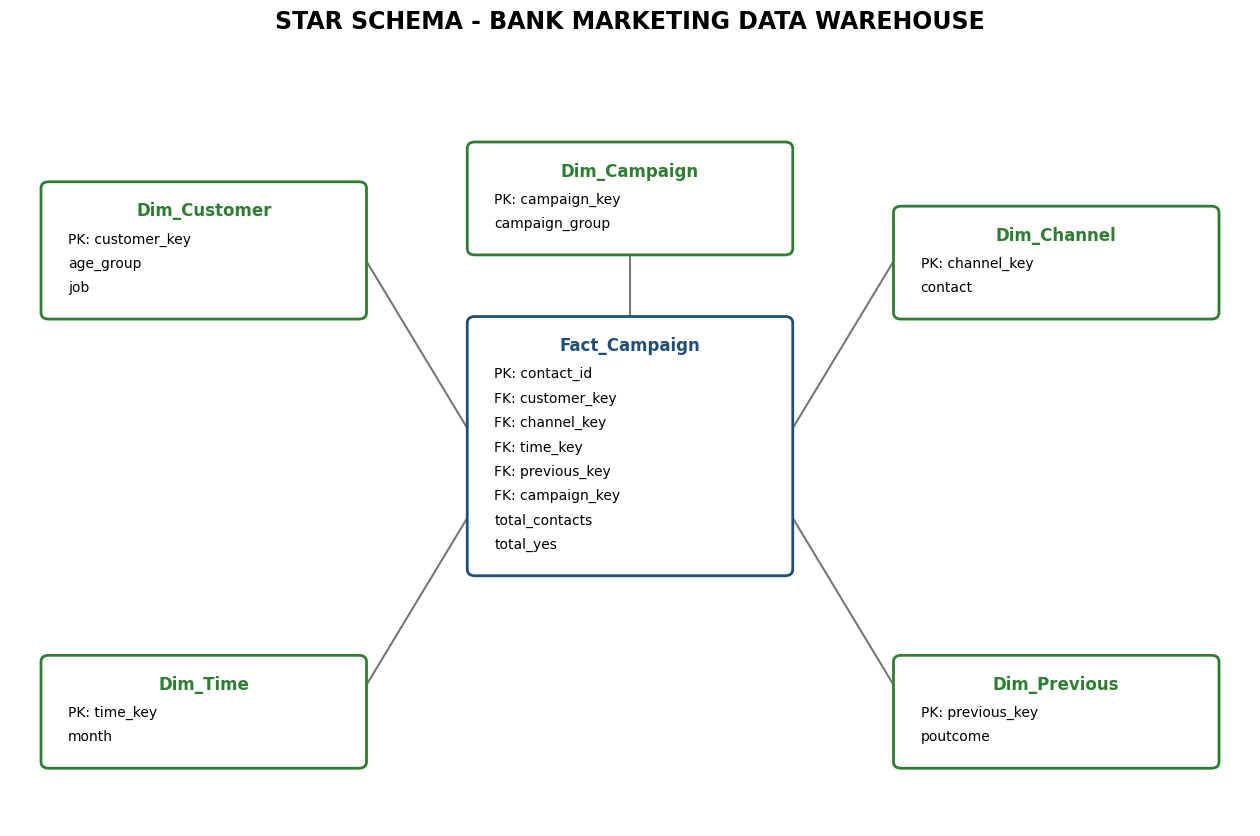

Đã tạo sơ đồ Star Schema thành công!


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(16, 10))
ax.set_xlim(0, 16)
ax.set_ylim(0, 12)
ax.axis("off")

def draw_box(x, y, title, fields, color):
    width = 4
    height = 0.8 + len(fields) * 0.38

    box = FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.1",
        facecolor="white",
        edgecolor=color,
        linewidth=2
    )
    ax.add_patch(box)

    ax.text(
        x + width/2, y + height - 0.35,
        title, ha="center", va="center",
        fontsize=12, fontweight="bold",
        color=color
    )

    for i, field in enumerate(fields):
        ax.text(
            x + 0.25,
            y + height - 0.85 - i*0.38,
            field, fontsize=10
        )

# Bảng Fact ở trung tâm
draw_box(6, 4, "Fact_Campaign", [
    "PK: contact_id",
    "FK: customer_key",
    "FK: channel_key",
    "FK: time_key",
    "FK: previous_key",
    "FK: campaign_key",
    "total_contacts",
    "total_yes"
], "#1f4e79")

# Các bảng Dimension
draw_box(0.5, 8, "Dim_Customer", [
    "PK: customer_key",
    "age_group",
    "job"
], "#2e7d32")

draw_box(11.5, 8, "Dim_Channel", [
    "PK: channel_key",
    "contact"
], "#2e7d32")

draw_box(0.5, 1, "Dim_Time", [
    "PK: time_key",
    "month"
], "#2e7d32")

draw_box(11.5, 1, "Dim_Previous", [
    "PK: previous_key",
    "poutcome"
], "#2e7d32")

draw_box(6, 9, "Dim_Campaign", [
    "PK: campaign_key",
    "campaign_group"
], "#2e7d32")

# Các đường liên kết
connections = [
    ((4.5, 9), (6, 6)),
    ((11.5, 9), (10, 6)),
    ((4.5, 2), (6, 5)),
    ((11.5, 2), (10, 5)),
    ((8, 9), (8, 7.9))
]

for start, end in connections:
    ax.plot(
        [start[0], end[0]],
        [start[1], end[1]],
        color="#777777",
        linewidth=1.5,
        zorder=0
    )

ax.set_title(
    "STAR SCHEMA - BANK MARKETING DATA WAREHOUSE",
    fontsize=17,
    fontweight="bold",
    pad=20
)

plt.savefig(
    "Figure_4_1_Star_Schema.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Đã tạo sơ đồ Star Schema thành công!")

---
# CHƯƠNG 5

# Chương V – Khai phá CAR

Chạy tất cả → chọn `bank_selected_17_features.csv` ở cell đầu → tải ZIP kết quả.

## Môi trường và dữ liệu đầu vào

In [ ]:
import importlib.util
from pathlib import Path

if importlib.util.find_spec("numba") is None:
    import site
    import subprocess
    import sys

    install = subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "numba"],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.PIPE,
        text=True,
    )
    if install.returncode:
        raise RuntimeError(install.stderr.strip())
    site.addsitedir(site.getusersitepackages())
    importlib.invalidate_caches()

csv_path = Path('bank_selected_17_features.csv')
if not csv_path.is_file():
    try:
        from google.colab import files as colab_files
    except ImportError:
        raise FileNotFoundError('Thiếu bank_selected_17_features.csv') from None
    uploaded = colab_files.upload()
    if len(uploaded) != 1:
        raise ValueError('Chọn đúng một tệp CSV gồm 17 biến và cột y.')
    csv_path = Path(next(iter(uploaded)))


## 1. MDLP

In [ ]:
"""CAR mining and feature generation for Chapter V."""

import argparse
import gc
import hashlib
import io
import json
import re
import sqlite3
import tempfile
import zipfile
from decimal import Decimal, ROUND_CEILING
from functools import lru_cache, cmp_to_key
from fractions import Fraction
from itertools import product
from math import sqrt
from pathlib import Path
from statistics import NormalDist

import numpy as np
import pandas as pd
from numba import njit, prange, types
from numba.typed import Dict
from scipy.special import xlogy

_PEP_KEY = types.UniTuple(types.uint64, 4)


def _min_count(n, support):
    return int((Decimal(str(support)) * n).to_integral_value(rounding=ROUND_CEILING))


def _pack(values):
    return int.from_bytes(
        np.packbits(np.asarray(values, dtype=bool), bitorder="little").tobytes(),
        "little",
    )


def _mining_input(encoded, supports):
    names = sorted(c for c in encoded.columns if c not in {"y=no", "y=yes"})
    if len(names) > 256:
        raise ValueError("Bản mã hóa này hỗ trợ tối đa 256 item điều kiện.")

    n = len(encoded)
    thresholds = [_min_count(n, support) for support in supports]
    bits = [_pack(encoded[c].to_numpy(dtype=bool)) for c in names]
    labels = [_pack(encoded[c].to_numpy(dtype=bool)) for c in ("y=no", "y=yes")]
    return names, n, thresholds, bits, labels


def entropy(counts):
    p = counts / counts.sum(axis=-1, keepdims=True)
    return -xlogy(p, p).sum(axis=-1) / np.log(2)


def mdlp_cuts(x, y):
    values, groups = np.unique(np.asarray(x, dtype=float), return_inverse=True)
    y = np.asarray(y, dtype=int)
    counts = np.column_stack(
        [np.bincount(groups, weights=(y == c), minlength=len(values)) for c in (0, 1)]
    )

    def partition(lo, hi):
        freq = counts[lo:hi]
        total = freq.sum(axis=0)
        n = total.sum()
        k = np.count_nonzero(total)

        if hi - lo < 2 or k < 2:
            return []

        left = freq.cumsum(axis=0)[:-1]
        right = total - left
        h, hl, hr = entropy(total), entropy(left), entropy(right)
        gain = h - (left.sum(axis=1) * hl + right.sum(axis=1) * hr) / n

        j = int(gain.argmax())
        kl = np.count_nonzero(left[j])
        kr = np.count_nonzero(right[j])
        delta = np.log2(3**k - 2) - k * h + kl * hl[j] + kr * hr[j]

        if gain[j] <= (np.log2(n - 1) + delta) / n:
            return []

        pos = lo + j + 1
        cut = float(values[pos - 1] + (values[pos] - values[pos - 1]) / 2)
        return partition(lo, pos) + [cut] + partition(pos, hi)

    return partition(0, len(values))




## 2. Apriori và Eclat

In [ ]:
def apriori_car_disk(encoded, supports, db_path):
    names, n, thresholds, bits, labels = _mining_input(encoded, supports)
    minimum = min(thresholds)

    db = sqlite3.connect(db_path)
    db.execute("PRAGMA cache_size=-16384")
    db.execute("PRAGMA temp_store=FILE")
    db.execute("PRAGMA mmap_size=0")
    db.executescript("""
        DROP TABLE IF EXISTS patterns;
        DROP TABLE IF EXISTS prev;
        DROP TABLE IF EXISTS next;
        DROP TABLE IF EXISTS metadata;

        CREATE TABLE patterns(
            items BLOB PRIMARY KEY,
            body_n INTEGER, no_n INTEGER, yes_n INTEGER
        ) WITHOUT ROWID;

        CREATE TABLE prev(
            items BLOB PRIMARY KEY,
            prefix BLOB, last INTEGER, mask INTEGER
        ) WITHOUT ROWID;

        CREATE TABLE metadata(
            key TEXT PRIMARY KEY, value TEXT
        );
    """)
    db.executemany(
        "INSERT INTO metadata VALUES (?, ?)",
        [
            ("status", "running"),
            ("item_names", json.dumps(names)),
            ("n_train", str(n)),
            ("minsup", str(min(supports))),
        ],
    )
    db.commit()

    @lru_cache(maxsize=2048)
    def body_bits(key):
        if len(key) == 1:
            return bits[key[0]]
        return body_bits(key[:-1]) & bits[key[-1]]

    counts = [0] * len(supports)
    longest = [0] * len(supports)
    batch = []

    def flush():
        db.executemany(
            "INSERT INTO next VALUES (?, ?, ?, ?)", (row[:4] for row in batch)
        )
        db.executemany(
            "INSERT INTO patterns VALUES (?, ?, ?, ?)",
            ((r[0], r[4], r[5], r[6]) for r in batch),
        )
        batch.clear()

    def save(key, mask):
        tids = body_bits(key)
        no_n, yes_n = [(tids & label).bit_count() for label in labels]
        mask &= int(no_n >= minimum) | (int(yes_n >= minimum) << 1)
        if not mask:
            return

        batch.append((key, key[:-1], key[-1], mask, tids.bit_count(), no_n, yes_n))

        for i, threshold in enumerate(thresholds):
            found = int(no_n >= threshold) + int(yes_n >= threshold)
            counts[i] += found
            if found:
                longest[i] = max(longest[i], len(key) + 1)

        if len(batch) == 1000:
            flush()

    def start_level():
        db.execute("""
            CREATE TABLE next(
                items BLOB PRIMARY KEY,
                prefix BLOB, last INTEGER, mask INTEGER
            ) WITHOUT ROWID
        """)

    def finish_level():
        flush()
        size = db.execute("SELECT count(*) FROM next").fetchone()[0]
        db.executescript("""
            DROP TABLE prev;
            ALTER TABLE next RENAME TO prev;
            CREATE INDEX prev_prefix ON prev(prefix, last);
        """)
        db.commit()
        return size

    start_level()
    for item in range(len(names)):
        save(bytes([item]), 3)
    size = finish_level()

    while size:
        start_level()

        @lru_cache(maxsize=8192)
        def previous_mask(key):
            row = db.execute("SELECT mask FROM prev WHERE items=?", (key,)).fetchone()
            return row[0] if row else 0

        candidates = db.execute("""
            SELECT a.items, b.last, (a.mask & b.mask)
            FROM prev AS a JOIN prev AS b
              ON a.prefix = b.prefix AND a.last < b.last
            WHERE (a.mask & b.mask) > 0
        """)

        for prefix, last, mask in candidates:
            key = prefix + bytes([last])

            for j in range(len(key) - 2):
                mask &= previous_mask(key[:j] + key[j + 1 :])
                if not mask:
                    break

            if mask:
                save(key, mask)

        candidates.close()
        previous_mask.cache_clear()
        size = finish_level()

    db.execute("UPDATE metadata SET value='complete' WHERE key='status'")
    db.commit()
    db.close()
    body_bits.cache_clear()

    return pd.DataFrame(
        {
            "minsup (%)": np.array(supports) * 100,
            "Số bản ghi tối thiểu": thresholds,
            "Tập phổ biến chứa nhãn": counts,
            "Độ dài lớn nhất (gồm nhãn)": longest,
        }
    )


def eclat_car_disk(encoded, supports, db_path):
    names, n, thresholds, bits, labels = _mining_input(encoded, supports)
    minimum = min(thresholds)

    db = sqlite3.connect(db_path)
    db.execute("PRAGMA cache_size=-16384")
    db.execute("PRAGMA temp_store=FILE")
    db.execute("PRAGMA mmap_size=0")
    db.executescript("""
        DROP TABLE IF EXISTS patterns;
        DROP TABLE IF EXISTS metadata;

        CREATE TABLE patterns(
            items BLOB PRIMARY KEY,
            body_n INTEGER, no_n INTEGER, yes_n INTEGER
        ) WITHOUT ROWID;

        CREATE TABLE metadata(
            key TEXT PRIMARY KEY, value TEXT
        );
    """)
    db.executemany(
        "INSERT INTO metadata VALUES (?, ?)",
        [
            ("status", "running"),
            ("item_names", json.dumps(names)),
            ("n_train", str(n)),
            ("minsup", str(min(supports))),
        ],
    )
    db.commit()

    batch = []
    counts = [0] * len(supports)
    longest = [0] * len(supports)

    def flush():
        db.executemany("INSERT INTO patterns VALUES (?, ?, ?, ?)", batch)
        batch.clear()

    def visit(prefix, extensions):
        for j, (item, tids, no_n, yes_n) in enumerate(extensions):
            key = prefix + bytes([item])
            batch.append((key, tids.bit_count(), no_n, yes_n))

            for i, threshold in enumerate(thresholds):
                found = int(no_n >= threshold) + int(yes_n >= threshold)
                counts[i] += found
                if found:
                    longest[i] = max(longest[i], len(key) + 1)

            if len(batch) == 1000:
                flush()

            children = []
            for other, other_tids, other_no, other_yes in extensions[j + 1 :]:
                if (no_n < minimum or other_no < minimum) and (
                    yes_n < minimum or other_yes < minimum
                ):
                    continue

                intersection = tids & other_tids
                c_no, c_yes = [(intersection & label).bit_count() for label in labels]
                if max(c_no, c_yes) >= minimum:
                    children.append((other, intersection, c_no, c_yes))

            if children:
                visit(key, children)

    roots = []
    for item, tids in enumerate(bits):
        no_n, yes_n = [(tids & label).bit_count() for label in labels]
        if max(no_n, yes_n) >= minimum:
            roots.append((item, tids, no_n, yes_n))

    visit(b"", roots)
    flush()
    db.execute("UPDATE metadata SET value='complete' WHERE key='status'")
    db.commit()
    db.close()

    return pd.DataFrame(
        {
            "minsup (%)": np.array(supports) * 100,
            "Số bản ghi tối thiểu": thresholds,
            "Tập phổ biến chứa nhãn": counts,
            "Độ dài lớn nhất (gồm nhãn)": longest,
        }
    )


def verify_same_databases(eclat_path, apriori_path):
    db = sqlite3.connect(eclat_path)
    db.execute("PRAGMA cache_size=-16384")
    db.execute("ATTACH DATABASE ? AS apr", (str(apriori_path),))

    e_meta = dict(db.execute("SELECT * FROM metadata"))
    a_meta = dict(db.execute("SELECT * FROM apr.metadata"))

    if e_meta != a_meta or e_meta.get("status") != "complete":
        db.close()
        raise ValueError("Hai nhánh khác cấu hình hoặc chưa hoàn tất.")

    mismatch = db.execute("""
        SELECT 1 FROM patterns AS e
        LEFT JOIN apr.patterns AS a ON a.items = e.items
        WHERE a.items IS NULL
           OR e.body_n != a.body_n
           OR e.no_n != a.no_n
           OR e.yes_n != a.yes_n
        LIMIT 1
    """).fetchone()

    missing = db.execute("""
        SELECT 1 FROM apr.patterns AS a
        LEFT JOIN patterns AS e ON e.items = a.items
        WHERE e.items IS NULL
        LIMIT 1
    """).fetchone()
    db.close()

    if mismatch or missing:
        raise ValueError("Eclat và Apriori khác tập phổ biến hoặc số đếm.")
    return True




## 3. CAR và PEP

In [ ]:
def generate_cars_sql(db_path, encoded, supports, confidences):
    if not Path(db_path).is_file():
        raise FileNotFoundError("Chưa có tệp kết quả khai phá.")

    db = sqlite3.connect(db_path)
    db.execute("PRAGMA cache_size=-16384")
    db.execute("PRAGMA temp_store=FILE")
    db.execute("PRAGMA mmap_size=0")

    meta = dict(db.execute("SELECT * FROM metadata"))
    n = len(encoded)
    names = sorted(c for c in encoded.columns if c not in {"y=no", "y=yes"})

    if (
        meta.get("status") != "complete"
        or int(meta["n_train"]) != n
        or json.loads(meta["item_names"]) != names
    ):
        db.close()
        raise ValueError("Kết quả khai phá chưa hoàn tất hoặc khác train.")

    if Decimal(str(min(supports))) < Decimal(meta["minsup"]):
        db.close()
        raise ValueError("Minsup yêu cầu thấp hơn ngưỡng đã khai phá.")

    n_yes = int(encoded["y=yes"].sum())
    n_no = int(encoded["y=no"].sum())

    if n_yes + n_no != n:
        db.close()
        raise ValueError("Nhãn train không hợp lệ.")

    ratio = Fraction(str(min(confidences)))

    db.executescript("""
        DROP VIEW IF EXISTS car_metrics;
        DROP TABLE IF EXISTS cars;
        DROP TABLE IF EXISTS car_metadata;

        CREATE TABLE cars(
            items BLOB PRIMARY KEY,
            consequent TEXT,
            body_n INTEGER,
            rule_n INTEGER
        ) WITHOUT ROWID;

        CREATE TABLE car_metadata(
            key TEXT PRIMARY KEY, value TEXT
        );
    """)

    db.executemany(
        "INSERT INTO car_metadata VALUES (?, ?)",
        [
            ("status", "running"),
            ("minsup", str(min(supports))),
            ("minconf", str(min(confidences))),
            ("n_train", str(n)),
            ("n_yes", str(n_yes)),
            ("n_no", str(n_no)),
            ("policy", "highest confidence per antecedent; ties -> no"),
        ],
    )
    db.commit()

    db.execute(
        """
        INSERT INTO cars
        SELECT items,
            CASE WHEN yes_n > no_n THEN 'yes' ELSE 'no' END,
            body_n,
            MAX(no_n, yes_n)
        FROM patterns
        WHERE MAX(no_n, yes_n) >= ?
          AND MAX(no_n, yes_n) * ? >= body_n * ?
    """,
        (_min_count(n, min(supports)), ratio.denominator, ratio.numerator),
    )

    db.execute(f"""
        CREATE VIEW car_metrics AS
        SELECT items, consequent, body_n, rule_n,
            length(items) AS n_conditions,
            1.0 * rule_n / {n} AS support,
            1.0 * rule_n / body_n AS confidence,
            1.0 * rule_n * {n} / (
                body_n *
                CASE WHEN consequent = 'yes'
                     THEN {n_yes} ELSE {n_no} END
            ) AS lift
        FROM cars
    """)

    db.execute("""
        UPDATE car_metadata
        SET value = 'complete'
        WHERE key = 'status'
    """)
    db.commit()

    rows = []
    for support, confidence in product(supports, confidences):
        ratio = Fraction(str(confidence))

        total, yes, no = db.execute(
            """
            SELECT count(*),
                COALESCE(SUM(consequent = 'yes'), 0),
                COALESCE(SUM(consequent = 'no'), 0)
            FROM cars
            WHERE rule_n >= ?
              AND rule_n * ? >= body_n * ?
        """,
            (_min_count(n, support), ratio.denominator, ratio.numerator),
        ).fetchone()

        rows.append(
            {
                "minsup (%)": support * 100,
                "minconf (%)": confidence * 100,
                "CAR": total,
                "CAR yes": yes,
                "CAR no": no,
            }
        )

    db.close()
    return pd.DataFrame(rows)


@njit
def _pep_index(raw, offsets):
    size = len(offsets) - 1
    masks = np.zeros((size, 4), dtype=np.uint64)
    index = Dict.empty(key_type=_PEP_KEY, value_type=types.int64)

    for i in range(size):
        if offsets[i] == offsets[i + 1]:
            raise ValueError("Antecedent rỗng trong bảng patterns.")

        previous = -1

        for j in range(offsets[i], offsets[i + 1]):
            item = int(raw[j])

            if item <= previous:
                raise ValueError("Các item phải tăng dần và không trùng.")

            previous = item
            masks[i, item // 64] |= np.uint64(1) << np.uint64(item % 64)

        key = (masks[i, 0], masks[i, 1], masks[i, 2], masks[i, 3])
        index[key] = i

    return masks, index


@njit
def _pep_error(total, correct, cf, z):
    errors = total - correct

    if errors == 0:
        return 1.0 - cf ** (1.0 / total)

    if errors + 0.5 >= total:
        return 1.0

    f = (errors + 0.5) / total

    return (
        f
        + z * z / (2 * total)
        + z * sqrt(f * (1 - f) / total + z * z / (4 * total * total))
    ) / (1 + z * z / total)


@njit(parallel=True)
def _pep_errors(counts, cf, z):
    rates = np.empty((len(counts), 2), dtype=np.float64)

    for i in prange(len(counts)):
        for label in range(2):
            rates[i, label] = _pep_error(counts[i, 0], counts[i, label + 1], cf, z)

    return rates


@njit(parallel=True)
def _pep_filter(raw, offsets, masks, index, labels, rates, empty_rates):
    keep = np.zeros(len(labels), dtype=np.bool_)
    missing = np.zeros(len(labels), dtype=np.bool_)

    for i in prange(len(labels)):
        label = labels[i]

        if label < 0:
            continue

        error = rates[i, label]
        keep[i] = True

        a, b, c, d = (masks[i, 0], masks[i, 1], masks[i, 2], masks[i, 3])

        for j in range(offsets[i], offsets[i + 1]):
            item = int(raw[j])
            word = item // 64
            bit = np.uint64(1) << np.uint64(item % 64)

            parent = (
                a ^ (bit if word == 0 else np.uint64(0)),
                b ^ (bit if word == 1 else np.uint64(0)),
                c ^ (bit if word == 2 else np.uint64(0)),
                d ^ (bit if word == 3 else np.uint64(0)),
            )

            if offsets[i + 1] - offsets[i] == 1:
                parent_error = empty_rates[label]
            else:
                if parent not in index:
                    missing[i] = True
                    keep[i] = False
                    break

                parent_i = index[parent]
                parent_error = rates[parent_i, label]

            if error > parent_error:
                keep[i] = False
                break

    return keep, missing


def prune_cars_pep_fast(db_path, supports, confidences, cf=0.25):
    supports = tuple(supports)
    confidences = tuple(confidences)

    if not Path(db_path).is_file():
        raise FileNotFoundError(f"Chưa có tệp CAR: {db_path}")

    if not 0 < cf <= 0.5:
        raise ValueError("CF phải thuộc khoảng (0; 0,5].")

    if not supports or not confidences:
        raise ValueError("Lưới ngưỡng không được rỗng.")

    if any(not 0 < float(s) <= 1 for s in supports):
        raise ValueError("Minsup phải thuộc khoảng (0; 1].")

    if any(not 0 <= float(c) <= 1 for c in confidences):
        raise ValueError("Minconf phải thuộc khoảng [0; 1].")

    db = sqlite3.connect(str(db_path))

    try:
        meta = dict(db.execute("SELECT key,value FROM car_metadata"))

        if meta.get("status") != "complete":
            raise ValueError("Cần chạy xong cell 5.2.3 trước.")

        if Decimal(str(min(supports))) < Decimal(meta["minsup"]) or Decimal(
            str(min(confidences))
        ) < Decimal(meta["minconf"]):
            raise ValueError("Ngưỡng yêu cầu thấp hơn ngưỡng đã sinh CAR.")

        n = int(meta["n_train"])
        class_counts = [int(meta["n_no"]), int(meta["n_yes"])]

        if n <= 0 or sum(class_counts) != n:
            raise ValueError("Số lượng mẫu/lớp trong metadata không hợp lệ.")

        frame = pd.read_sql_query(
            """
            SELECT p.items, p.body_n, p.no_n, p.yes_n,
                   CASE c.consequent
                       WHEN 'no' THEN 0
                       WHEN 'yes' THEN 1
                       ELSE -1
                   END AS label,
                   c.body_n AS car_body,
                   c.rule_n
            FROM patterns AS p
            LEFT JOIN cars AS c ON c.items=p.items
            ORDER BY p.items
        """,
            db,
        )

        keys = frame["items"].tolist()

        counts = np.ascontiguousarray(
            frame[["body_n", "no_n", "yes_n"]].to_numpy(dtype=np.int64)
        )

        labels = frame["label"].to_numpy(dtype=np.int64)
        candidates = labels >= 0
        candidate_ids = np.flatnonzero(candidates)

        correct = np.zeros(len(labels), dtype=np.int64)
        correct[candidate_ids] = counts[candidate_ids, labels[candidate_ids] + 1]

        source_size = db.execute("SELECT COUNT(*) FROM cars").fetchone()[0]

        if len(candidate_ids) != source_size:
            raise ValueError("Có CAR bị thiếu patterns hoặc nhãn không hợp lệ.")

        if not np.array_equal(
            frame.loc[candidates, "car_body"].to_numpy(), counts[candidates, 0]
        ) or not np.array_equal(
            frame.loc[candidates, "rule_n"].to_numpy(), correct[candidates]
        ):
            raise ValueError("Số đếm trong cars và patterns không khớp.")

        if (
            np.any(counts < 0)
            or np.any(counts[:, 0] <= 0)
            or np.any(counts[:, 0] > n)
            or np.any(counts[:, 1] + counts[:, 2] != counts[:, 0])
        ):
            raise ValueError("Số đếm trong patterns không hợp lệ.")

        del frame, candidate_ids

        lengths = np.fromiter(map(len, keys), dtype=np.int64, count=len(keys))

        offsets = np.concatenate((np.zeros(1, dtype=np.int64), np.cumsum(lengths)))

        raw = np.frombuffer(b"".join(keys), dtype=np.uint8)
        masks, index = _pep_index(raw, offsets)

        z = NormalDist().inv_cdf(1 - cf)
        rates = _pep_errors(counts, cf, z)

        empty_rates = np.array(
            [_pep_error(n, class_counts[label], cf, z) for label in range(2)]
        )

        keep, missing = _pep_filter(
            raw, offsets, masks, index, labels, rates, empty_rates
        )

        if missing.any():
            raise ValueError("Thiếu tập con: hãy kiểm tra kết quả khai phá.")

        del masks, index, raw, offsets, empty_rates
        gc.collect()

        db.execute("BEGIN")

        with db:
            db.execute("DROP VIEW IF EXISTS car_metrics_pep")
            db.execute("DROP TABLE IF EXISTS cars_pep")
            db.execute("DROP TABLE IF EXISTS pep_metadata")

            db.execute("""
                CREATE TABLE cars_pep(
                    items BLOB PRIMARY KEY,
                    consequent TEXT,
                    body_n INTEGER,
                    rule_n INTEGER,
                    pep_error REAL
                ) WITHOUT ROWID
            """)

            db.executemany(
                "INSERT INTO cars_pep VALUES (?,?,?,?,?)",
                (
                    (
                        keys[i],
                        "yes" if labels[i] == 1 else "no",
                        int(counts[i, 0]),
                        int(correct[i]),
                        float(rates[i, labels[i]]),
                    )
                    for i in np.flatnonzero(keep)
                ),
            )

            db.execute("""
                CREATE TABLE pep_metadata(
                    key TEXT PRIMARY KEY,
                    value TEXT
                )
            """)

            db.executemany(
                "INSERT INTO pep_metadata VALUES (?,?)",
                [
                    ("status", "complete"),
                    ("method", "CBA pessimistic error pruning"),
                    ("cf", str(cf)),
                    ("compare_empty_antecedent", "true"),
                    ("minsup", meta["minsup"]),
                    ("minconf", meta["minconf"]),
                    ("engine", "Numba; full in-memory pattern index"),
                ],
            )

            db.execute("""
                CREATE VIEW car_metrics_pep AS
                SELECT m.*, p.pep_error
                FROM cars_pep AS p
                JOIN car_metrics AS m ON m.items=p.items
            """)

        rows = []

        for s, c in product(supports, confidences):
            minimum = _min_count(n, s)

            ratio = Fraction(str(c))

            if n * max(ratio.numerator, ratio.denominator) > np.iinfo(np.int64).max:
                raise ValueError("Minconf có quá nhiều chữ số thập phân.")

            eligible = (
                candidates
                & (correct >= minimum)
                & (correct * ratio.denominator >= counts[:, 0] * ratio.numerator)
            )

            selected = eligible & keep

            rows.append(
                {
                    "minsup (%)": float(s) * 100,
                    "minconf (%)": float(c) * 100,
                    "CAR trước": int(eligible.sum()),
                    "CAR sau": int(selected.sum()),
                    "CAR yes": int(np.count_nonzero(selected & (labels == 1))),
                    "CAR no": int(np.count_nonzero(selected & (labels == 0))),
                }
            )

        return pd.DataFrame(rows)

    finally:
        db.close()




## 4. Rời rạc hóa

In [ ]:
def fit_transform_discretization(df_train, df_val, df_test, features):
    """Fit MDLP on train and apply the same cuts to all splits."""
    features = list(features)
    frames = (df_train, df_val, df_test)
    if "y" in features or len(features) != len(set(features)):
        raise ValueError("Danh sách biến đầu vào không hợp lệ.")
    if not df_train["y"].isin(["yes", "no"]).all():
        raise ValueError("Nhãn train phải là yes/no.")
    numeric = [c for c in features if pd.api.types.is_numeric_dtype(df_train[c])]
    categorical = [c for c in features if c not in numeric]
    cuts = {}
    for c in numeric:
        valid = df_train[c].ne(999) if c == "pdays" else df_train[c].notna()
        cuts[c] = mdlp_cuts(df_train.loc[valid, c], df_train.loc[valid, "y"].eq("yes"))

    def transform(frame):
        if frame[features].isna().any().any():
            raise ValueError("Có dữ liệu thiếu trước rời rạc hóa.")
        result = frame[categorical].astype("string").copy()
        for c, points in cuts.items():
            edges = [-np.inf, *points, np.inf]
            labels = [f"({a:.12g},{b:.12g}]" for a, b in zip(edges[:-1], edges[1:])]
            values = frame[c].mask(frame[c].eq(999)) if c == "pdays" else frame[c]
            result[c] = pd.cut(values, edges, labels=labels, right=True).astype(
                "string"
            )
            if c == "pdays":
                result.loc[frame[c].eq(999), c] = "999"
        if result[features].isna().any().any():
            raise ValueError("Có giá trị chưa được rời rạc hóa.")
        return result[features]

    return (*[transform(frame) for frame in frames], cuts)


def format_item(item):
    column, value = item.split("=", 1)
    if column == "pdays" and value == "999":
        return "pdays_contacted = False (pdays = 999)"
    if column == "pdays" and value == "(-inf,inf]":
        return "pdays_contacted = True (pdays ≠ 999)"
    match = re.fullmatch(r"\(([^,]+),([^\]]+)\]", value)
    if match:
        lo, hi = match.groups()
        if lo == "-inf" and hi == "inf":
            return f"{column}: mọi giá trị hợp lệ"
        if lo == "-inf":
            return f"{column} ≤ {hi}"
        if hi == "inf":
            return f"{column} > {lo}"
        return f"{lo} < {column} ≤ {hi}"
    return f"{column} = {value}"




## 5. Chọn luật

In [ ]:
# Rule selection

BASE_FEATURES = [
    "age",
    "job",
    "marital",
    "education",
    "default",
    "contact",
    "month",
    "day_of_week",
    "campaign",
    "pdays",
    "previous",
    "poutcome",
    "emp.var.rate",
    "cons.price.idx",
    "cons.conf.idx",
    "euribor3m",
    "nr.employed",
]
CATEGORICAL_FEATURES = [
    "job",
    "marital",
    "education",
    "default",
    "contact",
    "month",
    "day_of_week",
    "poutcome",
]
MACRO_FEATURES = {
    "emp.var.rate",
    "cons.price.idx",
    "cons.conf.idx",
    "euribor3m",
    "nr.employed",
}
MINSUP_GRID = (0.005, 0.01, 0.02)
MINCONF_GRID = (0.50, 0.60, 0.70, 0.80)
RANDOM_STATE = 42
PEP_CF = 0.25
FINAL_MINSUP = 0.01
YES_MIN_BODY = 400


def _csa_compare(a, b):
    delta = a[3] * b[2] - b[3] * a[2]
    if delta:
        return -1 if delta > 0 else 1
    if a[3] != b[3]:
        return -1 if a[3] > b[3] else 1
    if len(a[0]) != len(b[0]):
        return -1 if len(a[0]) < len(b[0]) else 1
    return (a[0] > b[0]) - (a[0] < b[0])


def _no_compare(a, b):
    if a[2] != b[2]:
        return -1 if a[2] > b[2] else 1
    return _csa_compare(a, b)


def _bounded_macro_items(key, names):
    result = []
    for i in key:
        name, value = names[i].split("=", 1)
        if name in MACRO_FEATURES and not (
            value.startswith("(-inf,") or value.endswith(",inf]")
        ):
            result.append(names[i])
    return result


def select_three_cars(db_path, encoded_train):
    """Select three rules using training transactions only."""
    with sqlite3.connect(str(db_path)) as db:
        metadata = dict(db.execute("SELECT * FROM metadata"))
        car_meta = dict(db.execute("SELECT * FROM car_metadata"))
        pep_meta = dict(db.execute("SELECT * FROM pep_metadata"))
        if any(m.get("status") != "complete" for m in (metadata, car_meta, pep_meta)):
            raise ValueError("Khai phá, sinh CAR hoặc PEP chưa hoàn tất.")
        names = tuple(json.loads(metadata["item_names"]))
        rows = db.execute(
            "SELECT items, consequent, body_n, rule_n FROM cars_pep"
        ).fetchall()

    n = len(encoded_train)
    if n != int(car_meta["n_train"]):
        raise ValueError("Số dòng train không khớp backend.")
    needed = list(names) + ["y=no", "y=yes"]
    if not encoded_train.columns.is_unique or not set(needed).issubset(
        encoded_train.columns
    ):
        raise ValueError("Mã item không khớp backend.")
    values = encoded_train[needed].to_numpy()
    if pd.isna(values).any() or not np.isin(values, [0, 1]).all():
        raise ValueError("Item phải là Boolean hoặc 0/1.")
    bits = [_pack(encoded_train[c]) for c in names]
    label_bits = {c: _pack(encoded_train["y=" + c]) for c in ("no", "yes")}
    class_n = {c: v.bit_count() for c, v in label_bits.items()}
    all_bits = (1 << n) - 1
    if (
        label_bits["no"] & label_bits["yes"]
        or (label_bits["no"] | label_bits["yes"]) != all_bits
        or class_n != {"no": int(car_meta["n_no"]), "yes": int(car_meta["n_yes"])}
    ):
        raise ValueError("Nhãn train không khớp backend.")

    @lru_cache(maxsize=None)
    def coverage_mask(key):
        mask = all_bits
        for i in key:
            if i >= len(bits):
                raise ValueError("Mã item không hợp lệ.")
            mask &= bits[i]
        return mask

    minimum = _min_count(n, FINAL_MINSUP)
    candidates = [
        r
        for r in rows
        if r[0] and r[1] in class_n and r[3] >= minimum and r[3] * 2 >= r[2]
    ]
    no_pool = [
        r
        for r in candidates
        if r[1] == "no" and r[3] * 100 >= 95 * r[2] and len(r[0]) >= 2
    ]
    no_pool.sort(key=cmp_to_key(_no_compare))
    if not no_pool:
        raise ValueError("Không có luật no từ hai điều kiện với Confidence >= 95%.")
    chosen_no = no_pool[0]

    yes_all = [
        r
        for r in candidates
        if r[1] == "yes"
        and len(r[0]) >= 2
        and r[2] >= YES_MIN_BODY
        and r[3] * n >= 4 * r[2] * class_n["yes"]
    ]
    yes_all.sort(key=cmp_to_key(_csa_compare))

    def conflict_attributes(a, b):
        left = dict(names[i].split("=", 1) for i in a[0])
        right = dict(names[i].split("=", 1) for i in b[0])
        return sorted(c for c in left.keys() & right.keys() if left[c] != right[c])

    pairs = []
    for i, a in enumerate(yes_all):
        for b in yes_all[i + 1 :]:
            if coverage_mask(a[0]) & coverage_mask(b[0]):
                continue
            if not conflict_attributes(a, b):
                continue
            bounded = _bounded_macro_items(a[0], names) + _bounded_macro_items(
                b[0], names
            )
            pairs.append((a, b, bounded))

    if not pairs:
        raise ValueError(
            "Không có cặp CAR yes tách biệt đạt minsup 1% và Coverage tối thiểu."
        )

    def pair_stage(p):
        a, b, bounded = p
        short = len(a[0]) <= 3 and len(b[0]) <= 3
        return (0 if not bounded else 1 if len(bounded) == 1 else 2, 0 if short else 1)

    stages = [
        ("no_bounded_macro_short", (0, 0)),
        ("no_bounded_macro_long", (0, 1)),
        ("one_bounded_macro_short", (1, 0)),
        ("one_bounded_macro_long", (1, 1)),
        ("multiple_bounded_macro_short", (2, 0)),
        ("multiple_bounded_macro_long", (2, 1)),
    ]
    stage_counts = [
        {"stage": name, "pairs": sum(pair_stage(p) == key for p in pairs)}
        for name, key in stages
    ]
    chosen_stage, stage_key = next(
        (name, key) for name, key in stages if any(pair_stage(p) == key for p in pairs)
    )
    a, b, bounded = next(p for p in pairs if pair_stage(p) == stage_key)
    pair = (a, b)
    audit = {
        "fit_and_select_split": "train",
        "validation_role": "report_only",
        "test_used_for_selection": False,
        "no_eligible": len(no_pool),
        "final_minsup": FINAL_MINSUP,
        "final_min_rule_n": minimum,
        "yes_confidence_min": 0.50,
        "yes_lift_min": 4.0,
        "yes_min_body": YES_MIN_BODY,
        "yes_eligible": len(yes_all),
        "disjoint_pairs": len(pairs),
        "stages": stage_counts,
        "selected_stage": chosen_stage,
        "no_priority": ["coverage_desc", "confidence_desc", "length_asc", "item_id"],
        "yes_priority": ["confidence_desc", "support_desc", "length_asc", "item_id"],
        "pair_priority": [
            "fewest_bounded_macro_intervals",
            "two_or_three_conditions",
            "first_rule_csa",
            "second_rule_csa",
        ],
        "yes_overlap_max": 0.0,
        "require_conflicting_items": True,
        "bounded_macro_exception": bounded,
        "disjoint_attributes": conflict_attributes(*pair),
        "coverage_exception": False,
    }

    selected = []
    for number, r in enumerate((chosen_no, *pair), 1):
        key, label, body, correct = r
        mask = coverage_mask(key)
        if (
            mask.bit_count() != body
            or (mask & label_bits[label]).bit_count() != correct
            or correct < minimum
        ):
            raise ValueError("Số đếm luật không khớp train.")
        selected.append(
            {
                "feature": f"Rule_{number}",
                "items": list(key),
                "antecedent": [names[i] for i in key],
                "display_antecedent": " AND ".join(format_item(names[i]) for i in key),
                "consequent": label,
                "body_n": body,
                "rule_n": correct,
                "support": correct / n,
                "confidence": correct / body,
                "lift": correct * n / (body * class_n[label]),
                "coverage": body / n,
                "n_conditions": len(key),
            }
        )
    masks = [coverage_mask(r[0]) for r in (chosen_no, *pair)]
    if len(set(masks)) != 3 or any((all_bits ^ m) in masks for m in masks):
        raise ValueError("Feature trùng hoặc bù hoàn toàn trên train.")
    cross = (masks[1] & masks[2]).bit_count()
    if cross != 0 or not conflict_attributes(*pair):
        raise ValueError("Hai CAR yes chưa loại trừ nhau.")
    audit.update(
        yes_intersection_n=cross,
        yes_overlap=cross / min(pair[0][2], pair[1][2]),
        yes_union_n=(masks[1] | masks[2]).bit_count(),
        yes_union_correct_n=((masks[1] | masks[2]) & label_bits["yes"]).bit_count(),
        union_coverage=(masks[0] | masks[1] | masks[2]).bit_count() / n,
        train_class_counts=class_n,
    )
    return {"rules": selected, "audit": audit}




## 6. Tạo feature

In [ ]:
# Feature generation


def generate_rule_features(df_disc, rules):
    if "y" in df_disc.columns:
        raise ValueError("Không truyền y vào hàm tạo feature.")
    if [r["feature"] for r in rules] != ["Rule_1", "Rule_2", "Rule_3"]:
        raise ValueError("Cần đúng Rule_1, Rule_2 và Rule_3.")
    result = pd.DataFrame(index=df_disc.index)
    for rule in rules:
        match = pd.Series(True, index=df_disc.index)
        if not rule["antecedent"]:
            raise ValueError("Vế trái rỗng.")
        for item in rule["antecedent"]:
            column, value = item.split("=", 1)
            if column == "y" or column not in df_disc or df_disc[column].isna().any():
                raise ValueError("Item không hợp lệ: " + item)
            match &= df_disc[column].astype(str).eq(value)
        result[rule["feature"]] = match.astype("uint8")
    return result


def evaluate_rules(df_disc, y, rules, split):
    if not df_disc.index.equals(y.index):
        raise ValueError("Sai chỉ mục đặc trưng và nhãn.")
    binary = generate_rule_features(df_disc, rules)
    n = len(binary)
    rows = []
    for rule in rules:
        match = binary[rule["feature"]].astype(bool)
        body = int(match.sum())
        correct = int((match & y.eq(rule["consequent"])).sum())
        prevalence = y.eq(rule["consequent"]).mean()
        confidence = correct / body if body else np.nan
        rows.append(
            {
                "feature": rule["feature"],
                "split": split,
                "rhs": rule["consequent"],
                "n": n,
                "body_n": body,
                "rule_n": correct,
                "support": correct / n,
                "confidence": confidence,
                "lift": confidence / prevalence if prevalence else np.nan,
                "coverage": body / n,
            }
        )
    return pd.DataFrame(rows)


def _json_ready(value):
    if isinstance(value, dict):
        return {str(k): _json_ready(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [_json_ready(v) for v in value]
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    return value


def _write_json(path, value):
    path.write_text(
        json.dumps(_json_ready(value), ensure_ascii=False, indent=2), encoding="utf-8"
    )


def verify_methods(paths, tables):
    verify_same_databases(paths["Eclat"], paths["Apriori"])
    with sqlite3.connect(str(paths["Eclat"])) as db:
        db.execute("ATTACH DATABASE ? AS apr", (str(paths["Apriori"]),))
        for table, fields in [
            ("cars", "items,consequent,body_n,rule_n"),
            ("cars_pep", "items,consequent,body_n,rule_n,pep_error"),
        ]:
            for a, b in [("main", "apr"), ("apr", "main")]:
                mismatch = db.execute(
                    f"SELECT 1 FROM (SELECT {fields} FROM {a}.{table} "
                    f"EXCEPT SELECT {fields} FROM {b}.{table}) LIMIT 1"
                ).fetchone()
                if mismatch is not None:
                    raise ValueError("Apriori/Eclat khác bảng " + table)
    for stage in ("frequent", "cars", "pep"):
        pd.testing.assert_frame_equal(tables["Apriori"][stage], tables["Eclat"][stage])




## 7. Pipeline

In [ ]:
# Pipeline


def run_pipeline(
    csv_path="bank_selected_17_features.csv", output_dir="Chuong_5_Ket_qua"
):
    from sklearn.model_selection import train_test_split

    csv_path = Path(csv_path)
    if not csv_path.is_file():
        try:
            from google.colab import files
        except ImportError:
            raise FileNotFoundError(csv_path) from None
        uploaded = files.upload()
        if len(uploaded) != 1:
            raise ValueError("Chọn đúng một CSV gồm 17 biến và y.")
        csv_path = Path(next(iter(uploaded)))
    raw_bytes = csv_path.read_bytes()
    df = pd.read_csv(io.BytesIO(raw_bytes))
    if not df.columns.is_unique or set(df.columns) != set(BASE_FEATURES + ["y"]):
        raise ValueError("CSV phải có đúng 17 biến gốc và nhãn y.")
    df = df[BASE_FEATURES + ["y"]].copy()
    numeric = [c for c in BASE_FEATURES if c not in CATEGORICAL_FEATURES]
    df[numeric] = df[numeric].apply(pd.to_numeric, errors="raise")
    if (
        df.isna().any().any()
        or not np.isfinite(df[numeric]).all().all()
        or set(df.y.unique()) != {"no", "yes"}
    ):
        raise ValueError("Dữ liệu thiếu, không hữu hạn hoặc nhãn không hợp lệ.")

    ids = np.arange(len(df))
    train_ids, temp_ids = train_test_split(
        ids, test_size=1 - 0.6, stratify=df.y, random_state=RANDOM_STATE
    )
    val_ids, test_ids = train_test_split(
        temp_ids, test_size=0.5, stratify=df.iloc[temp_ids].y, random_state=RANDOM_STATE
    )
    split_ids = {"train": train_ids, "validation": val_ids, "test": test_ids}
    np.testing.assert_array_equal(
        np.sort(np.concatenate(list(split_ids.values()))), ids
    )
    data = {s: df.iloc[i].copy() for s, i in split_ids.items()}
    train_disc, val_disc, test_disc, cuts = fit_transform_discretization(
        data["train"], data["validation"], data["test"], BASE_FEATURES
    )
    discrete = {"train": train_disc, "validation": val_disc, "test": test_disc}
    encoded = pd.get_dummies(
        train_disc.astype(str).assign(y=data["train"].y), prefix_sep="=", dtype=bool
    )
    encoded = encoded.reindex(sorted(encoded.columns), axis=1)
    if not encoded.sum(axis=1).eq(len(BASE_FEATURES) + 1).all():
        raise ValueError("Mã hóa giao dịch sai cấu trúc.")

    output = Path(output_dir)
    output.mkdir(parents=True, exist_ok=True)
    paths, tables = {}, {}
    with tempfile.TemporaryDirectory(prefix="chapter5_backend_") as temp_backend:
        backend = Path(temp_backend)
        for method, miner in [("Apriori", apriori_car_disk), ("Eclat", eclat_car_disk)]:
            path = backend / (method.lower() + "_car.sqlite")
            frequent = miner(encoded, MINSUP_GRID, str(path))
            cars = generate_cars_sql(str(path), encoded, MINSUP_GRID, MINCONF_GRID)
            pep = prune_cars_pep_fast(str(path), MINSUP_GRID, MINCONF_GRID, cf=PEP_CF)
            paths[method] = path
            tables[method] = {"frequent": frequent, "cars": cars, "pep": pep}
            for stage, frame in tables[method].items():
                frame.to_csv(
                    output / f"{method}_{stage}.csv", index=False, encoding="utf-8-sig"
                )
        verify_methods(paths, tables)
        selected = {m: select_three_cars(p, encoded) for m, p in paths.items()}
        if selected["Apriori"] != selected["Eclat"]:
            raise ValueError("Hai phương pháp chọn ba luật khác nhau.")

    rules = selected["Apriori"]["rules"]
    locked_bytes = json.dumps(rules, sort_keys=True, ensure_ascii=False).encode("utf-8")
    locked_hash = hashlib.sha256(locked_bytes).hexdigest()
    _write_json(output / "selected_rules.json", selected)
    _write_json(output / "selection_audit.json", selected["Apriori"]["audit"])
    metrics = pd.concat(
        [
            evaluate_rules(discrete[s], data[s].y, rules, s)
            for s in ("train", "validation")
        ],
        ignore_index=True,
    )
    confidence_train = metrics.query("split == 'train'").set_index("feature").confidence
    metrics["confidence_drop_pp"] = (
        metrics.feature.map(confidence_train) - metrics.confidence
    ) * 100
    metrics["drop_over_10pp"] = metrics.confidence_drop_pp > 10
    if (
        hashlib.sha256(
            json.dumps(rules, sort_keys=True, ensure_ascii=False).encode()
        ).hexdigest()
        != locked_hash
    ):
        raise ValueError("Định nghĩa luật bị thay đổi sau đánh giá validation.")

    x_a = {s: f[BASE_FEATURES].copy() for s, f in data.items()}
    y = {s: f.y.copy() for s, f in data.items()}
    binary = {
        m: {s: generate_rule_features(discrete[s], result["rules"]) for s in data}
        for m, result in selected.items()
    }
    x_b = {
        m: {s: pd.concat([x_a[s], binary[m][s]], axis=1) for s in data}
        for m in selected
    }
    summary = []
    for method in selected:
        for split in data:
            f = binary[method][split]
            if (f["Rule_2"] & f["Rule_3"]).any():
                raise ValueError("Hai feature yes còn giao nhau.")
            if (
                x_b[method][split].shape[1] != 20
                or not np.isin(f.to_numpy(), [0, 1]).all()
            ):
                raise ValueError("Feature B không hợp lệ.")
            pd.testing.assert_frame_equal(x_b[method][split][BASE_FEATURES], x_a[split])
            pd.testing.assert_frame_equal(x_b[method][split], x_b["Apriori"][split])
            summary.append(
                {
                    "method": method,
                    "split": split,
                    "rows": len(f),
                    "features_A": 17,
                    "features_B": 20,
                    **{c + "_pct": f[c].mean() * 100 for c in f},
                }
            )
    feature_summary = pd.DataFrame(summary)

    rule_table = pd.DataFrame(
        [
            {
                "feature": r["feature"],
                "antecedent": r["display_antecedent"],
                "rhs": r["consequent"],
                "n_conditions": r["n_conditions"],
                **{
                    k: r[k]
                    for k in (
                        "body_n",
                        "rule_n",
                        "support",
                        "confidence",
                        "lift",
                        "coverage",
                    )
                },
            }
            for r in rules
        ]
    )
    split_table = pd.concat(
        [pd.DataFrame({"source_row_id": split_ids[s], "split": s}) for s in data],
        ignore_index=True,
    )
    split_summary = pd.DataFrame(
        [
            {
                "split": s,
                "rows": len(f),
                "yes": int(f.y.eq("yes").sum()),
                "no": int(f.y.eq("no").sum()),
            }
            for s, f in data.items()
        ]
    )
    config = {
        "random_state": RANDOM_STATE,
        "split_fractions": [0.6, 0.2, 0.2],
        "split_order": "train vs remainder, then validation vs test; stratified y",
        "input_sha256": hashlib.sha256(raw_bytes).hexdigest(),
        "base_features": BASE_FEATURES,
        "features_A": 17,
        "features_each_B": 20,
        "excluded_from_predictors": ["source_row_id", "split", "y"],
        "mdlp": {
            "fit_split": "train",
            "cut_points": cuts,
            "interval_closed": "right",
            "label_number_format": ".12g",
            "special_values": {"pdays": [999]},
        },
        "minsup_grid": MINSUP_GRID,
        "minconf_grid": MINCONF_GRID,
        "pep_cf": PEP_CF,
        "selection": selected["Apriori"]["audit"],
        "rules_sha256": locked_hash,
        "classifier_fitted": False,
        "transform_uses_y": False,
        "same_B_data": True,
    }
    for name, frame in [
        ("selected_rules.csv", rule_table),
        ("train_validation_metrics.csv", metrics),
        ("feature_summary.csv", feature_summary),
        ("split_indices.csv", split_table),
        ("split_summary.csv", split_summary),
    ]:
        frame.to_csv(output / name, index=False, encoding="utf-8-sig")
    _write_json(output / "experiment_config.json", config)
    _write_json(output / "mdlp_cut_points.json", cuts)
    _write_json(
        output / "stage_tables.json",
        {
            m: {k: f.to_dict("records") for k, f in stages.items()}
            for m, stages in tables.items()
        },
    )

    handoff = output / "Chuong_5_Ban_giao_CAR.zip"
    with tempfile.TemporaryDirectory(prefix="ch5_") as temp:
        root = Path(temp)
        for s in data:
            for name, frame in [("A", x_a[s])] + [
                ("B_" + m, x_b[m][s]) for m in selected
            ]:
                dest = root / name / (s + ".csv")
                dest.parent.mkdir(parents=True, exist_ok=True)
                exported = frame.copy()
                exported.insert(0, "source_row_id", exported.index.to_numpy())
                exported["y"] = y[s]
                exported.to_csv(dest, index=False, encoding="utf-8-sig")
        for name in [
            "selected_rules.json",
            "selected_rules.csv",
            "selection_audit.json",
            "train_validation_metrics.csv",
            "feature_summary.csv",
            "split_indices.csv",
            "split_summary.csv",
            "experiment_config.json",
            "mdlp_cut_points.json",
            "stage_tables.json",
        ]:
            (root / name).write_bytes((output / name).read_bytes())
        (root / "README.txt").write_text(
            "A: 17 features. B_Apriori/B_Eclat: 20 features each.\n"
            "Rule_1=no; Rule_2/Rule_3=yes with disjoint antecedents.\n"
            "Train: MDLP, mining, PEP, selection. Validation: metrics. Test: features.\n"
            "source_row_id and y are not predictors.\n",
            encoding="utf-8",
        )
        _write_json(
            root / "checksums_sha256.json",
            {
                str(p.relative_to(root)): hashlib.sha256(p.read_bytes()).hexdigest()
                for p in sorted(root.rglob("*"))
                if p.is_file()
            },
        )
        with zipfile.ZipFile(handoff, "w", zipfile.ZIP_DEFLATED) as archive:
            for p in sorted(root.rglob("*")):
                if p.is_file():
                    archive.write(p, str(p.relative_to(root)))
    with zipfile.ZipFile(handoff) as archive:
        if archive.testzip() is not None:
            raise ValueError("Gói ZIP không hợp lệ.")
    return {
        "selected": selected,
        "rule_table": rule_table,
        "metrics": metrics,
        "feature_summary": feature_summary,
        "handoff": handoff,
        "X_A": x_a,
        "X_B": x_b,
        "y_splits": y,
        "split_ids": split_ids,
        "tables": tables,
        "cut_points": cuts,
    }


def show_results(result):
    for rule in result["selected"]["Apriori"]["rules"]:
        print(f'{rule["feature"]} → {rule["consequent"]}: {rule["display_antecedent"]}')
    metrics = result["metrics"][
        ["feature", "split", "support", "confidence", "lift", "coverage"]
    ].copy()
    for column in ("support", "confidence", "coverage"):
        metrics[column] = (metrics[column] * 100).round(2)
    metrics["lift"] = metrics["lift"].round(3)
    print(metrics.to_string(index=False))
    print(result["handoff"])




## Chạy khai phá và xem luật

In [ ]:
import csv
import tempfile
from pathlib import Path

ch5_columns = BASE_FEATURES + ["y"]

with Path(csv_path).open(encoding="utf-8-sig", newline="") as ch5_src, \
     tempfile.TemporaryDirectory(prefix="ch5_input_") as ch5_tmp:
    ch5_reader = csv.DictReader(ch5_src)
    ch5_header = ch5_reader.fieldnames or []
    ch5_missing = [c for c in ch5_columns if c not in ch5_header]
    if ch5_missing:
        raise ValueError(f"CSV thiếu các cột gốc: {ch5_missing}")
    if len(ch5_header) != len(set(ch5_header)):
        raise ValueError("CSV có tên cột trùng.")

    ch5_input = Path(ch5_tmp) / "bank_selected_17_features.csv"
    with ch5_input.open("w", encoding="utf-8-sig", newline="") as ch5_dst:
        ch5_writer = csv.DictWriter(
            ch5_dst, fieldnames=ch5_columns, extrasaction="ignore"
        )
        ch5_writer.writeheader()
        ch5_writer.writerows(ch5_reader)

    result = run_pipeline(ch5_input, "Chuong_5_Ket_qua")

show_results(result)


## Tải ZIP kết quả

Chạy riêng cell dưới để thử tải lại. Nếu trình duyệt không tải, mở biểu tượng thư mục bên trái trong Colab → `Chuong_5_Ket_qua` → chọn ba chấm ở `Chuong_5_Ban_giao_CAR.zip` → **Tải xuống**.

In [ ]:
from google.colab import files as colab_files

colab_files.download(str(result['handoff']))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# CHƯƠNG 6

# Chương 6. Phân loại và đánh giá
**Đồ án Khai phá dữ liệu – Bank Marketing**

Notebook này so sánh hai cấu hình trên cùng dữ liệu bàn giao từ Chương 5:
- **Mô hình A (Baseline):** 17 biến gốc đã chọn ở Chương 3.
- **Mô hình B:** 17 biến gốc + 3 đặc trưng `Rule_1`, `Rule_2`, `Rule_3` từ luật CAR.

Cấu trúc theo sườn đồ án: 6.1 Baseline A → 6.2 Mô hình B → 6.3 Lựa chọn mô hình → 6.4 So sánh công bằng → 6.5 Giải thích.

**Cách chạy trên Colab:** upload file `Chuong_5_Ban_giao_CAR_1.zip` vào khung Files, rồi chọn *Runtime → Run all*.

## 0. Chuẩn bị
### 0.1. Import thư viện và cố định tham số

In [ ]:
import os, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, confusion_matrix,
                             precision_recall_curve)
import sklearn
warnings.filterwarnings('ignore')
pd.set_option('display.float_format', lambda v: f'{v:.4f}')

RANDOM_STATE = 42
ZIP_FILE = 'Chuong_5_Ban_giao_CAR_1.zip'   # gói bàn giao của Chương 5
DATA_DIR = 'chuong5_ban_giao'               # thư mục giải nén
print('scikit-learn', sklearn.__version__)

scikit-learn 1.5.2


### 0.2. Giải nén gói bàn giao Chương 5
Gói gồm dữ liệu `A/` (17 biến), `B_Apriori/` và `B_Eclat/` (20 biến), kèm `selected_rules.csv` và `split_indices.csv`.

In [ ]:
# Kết nối tự động dữ liệu bàn giao từ Chương 5 khi chạy notebook ghép
if 'result' in globals() and isinstance(result, dict) and result.get('handoff'):
    ZIP_FILE = str(result['handoff'])
    print('Sử dụng gói bàn giao:', ZIP_FILE)

In [ ]:
if not os.path.isdir(DATA_DIR):
    with zipfile.ZipFile(ZIP_FILE) as z:
        z.extractall(DATA_DIR)
print(sorted(os.listdir(DATA_DIR)))
rules_df = pd.read_csv(f'{DATA_DIR}/selected_rules.csv', encoding='utf-8-sig')
rules_df[['feature', 'antecedent', 'rhs', 'body_n', 'support', 'confidence', 'lift', 'coverage']]

['A', 'B_Apriori', 'B_Eclat', 'README.txt', 'checksums_sha256.json', 'experiment_config.json', 'feature_summary.csv', 'mdlp_cut_points.json', 'selected_rules.csv', 'selected_rules.json', 'selection_audit.json', 'split_indices.csv', 'split_summary.csv', 'stage_tables.json', 'train_validation_metrics.csv']


,feature,antecedent,rhs,body_n,support,confidence,lift,coverage
0,Rule_1,29.5 < age ≤ 60.5 AND euribor3m > 3.1675,no,14766,0.5682,0.9510,1.0717,0.5975
1,Rule_2,contact = cellular AND 0.7155 < euribor3m ≤ 1....,yes,416,0.0113,0.6731,5.9745,0.0168
2,Rule_3,campaign ≤ 4.5 AND contact = cellular AND euri...,yes,479,0.0117,0.6054,5.3740,0.0194


### 0.3. Đọc dữ liệu train / validation / test
Dùng thư mục `B_Apriori` vì chứa cả 17 biến gốc lẫn 3 cột luật; `B_Eclat` có nội dung giống hệt (kiểm tra ở ô dưới).

In [ ]:
def load(split):
    d = pd.read_csv(f'{DATA_DIR}/B_Apriori/{split}.csv', encoding='utf-8-sig')
    d['y'] = (d['y'] == 'yes').astype(int)
    # pdays = 999 là mã "chưa từng liên hệ" -> biểu diễn nhị phân (thống nhất với Chương 5)
    d['pdays_contacted'] = (d['pdays'] != 999).astype(int)
    return d

train, val, test = load('train'), load('validation'), load('test')
for name, d in [('Train', train), ('Validation', val), ('Test', test)]:
    print(f'{name:<10} {len(d):>6} bản ghi | yes = {d.y.sum():>4} | tỷ lệ yes = {d.y.mean():.4f}')

Train       24712 bản ghi | yes = 2784 | tỷ lệ yes = 0.1127
Validation   8238 bản ghi | yes =  928 | tỷ lệ yes = 0.1126
Test         8238 bản ghi | yes =  928 | tỷ lệ yes = 0.1126


### 0.4. Kiểm tra tính nhất quán với Chương 3–5
1. B_Apriori và B_Eclat giống nhau.
2. Các dòng trong mỗi tập khớp `split_indices.csv`.
3. Ba cột Rule_1–3 tính lại từ định nghĩa luật trùng với dữ liệu bàn giao.

In [ ]:
for split in ['train', 'validation', 'test']:
    a = pd.read_csv(f'{DATA_DIR}/B_Apriori/{split}.csv', encoding='utf-8-sig')
    e = pd.read_csv(f'{DATA_DIR}/B_Eclat/{split}.csv', encoding='utf-8-sig')
    assert a.equals(e), split
split_idx = pd.read_csv(f'{DATA_DIR}/split_indices.csv', encoding='utf-8-sig')
for split, d in [('train', train), ('validation', val), ('test', test)]:
    assert set(d.source_row_id) == set(split_idx.loc[split_idx.split == split, 'source_row_id']), split

RULES = {
    'Rule_1': lambda d: (d.age > 29.5) & (d.age <= 60.5) & (d.euribor3m > 3.1675),
    'Rule_2': lambda d: (d.contact == 'cellular') & (d.euribor3m > 0.7155) & (d.euribor3m <= 1.092) & (d.poutcome == 'success'),
    'Rule_3': lambda d: (d.campaign <= 4.5) & (d.contact == 'cellular') & (d.euribor3m <= 0.7155),
}
for d in [train, val, test]:
    for k, f in RULES.items():
        assert (f(d).astype(int) == d[k]).all(), k
print('Dữ liệu bàn giao nhất quán: OK')

Dữ liệu bàn giao nhất quán: OK


### 0.5. Khai báo đặc trưng, pipeline và hàm đánh giá
- **8 biến phân loại** → One-Hot Encoding (giữ `unknown` như một mức riêng).
- **9 biến số** → StandardScaler.
- Pipeline chỉ học tham số từ tập train, tránh rò rỉ dữ liệu.

In [ ]:
CAT = ['job', 'marital', 'education', 'default', 'contact', 'month', 'day_of_week', 'poutcome']
NUM = ['age', 'campaign', 'pdays_contacted', 'previous', 'emp.var.rate',
       'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
CAR = ['Rule_1', 'Rule_2', 'Rule_3']
NUM_B = NUM + CAR
FEATS_A = NUM + CAT          # 17 biến gốc
FEATS_B = NUM_B + CAT        # 17 + 3 = 20 biến

def make_pipe(model, nums):
    pre = ColumnTransformer([
        ('num', StandardScaler(), nums),
        ('cat', OneHotEncoder(handle_unknown='ignore'), CAT)])
    return Pipeline([('pre', pre), ('clf', clone(model))])

MODELS = {
    'LogReg': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'DecisionTree': DecisionTreeClassifier(max_depth=6, min_samples_leaf=50,
                                           class_weight='balanced', random_state=RANDOM_STATE),
    'RandomForest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                           class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE),
}
SETTINGS = {'A': (NUM, FEATS_A), 'B': (NUM_B, FEATS_B)}

def scores(y, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return {'Precision': precision_score(y, pred), 'Recall': recall_score(y, pred),
            'F1': f1_score(y, pred), 'PR-AUC': average_precision_score(y, proba)}

print('Số biến: A =', len(FEATS_A), '| B =', len(FEATS_B))

Số biến: A = 17 | B = 20


### 0.6. Huấn luyện toàn bộ mô hình (chỉ trên tập train)
Mỗi mô hình được huấn luyện 2 lần (A và B) với cùng tham số; lưu lại xác suất dự đoán trên validation và test.

In [ ]:
fitted, proba = {}, {}
for m_name, model in MODELS.items():
    for s, (nums, feats) in SETTINGS.items():
        pipe = make_pipe(model, nums).fit(train[feats], train.y)
        fitted[(m_name, s)] = pipe
        for split, d in [('val', val), ('test', test), ('train', train)]:
            proba[(m_name, s, split)] = pipe.predict_proba(d[feats])[:, 1]

rows = []
for (m_name, s, split), p in proba.items():
    if split == 'train':
        continue
    y = val.y if split == 'val' else test.y
    rows.append({'Model': m_name, 'Setting': s, 'Split': split, **scores(y, p)})
results = pd.DataFrame(rows)
n_cols = {s: len(fitted[('LogReg', s)].named_steps['pre'].get_feature_names_out()) for s in 'AB'}
print('Số cột sau mã hóa:', n_cols)

Số cột sau mã hóa: {'A': 56, 'B': 59}


## 6.1. Baseline A: feature gốc đã chọn → Classification

In [ ]:
res_A = results[results.Setting == 'A'].pivot_table(index=['Model', 'Split'],
                                                   values=['Precision', 'Recall', 'F1', 'PR-AUC'])
res_A[['Precision', 'Recall', 'F1', 'PR-AUC']]

Precision  Recall     F1  PR-AUC
Model        Split                                  
DecisionTree test      0.3906  0.6002 0.4732  0.4372
             val       0.4052  0.6099 0.4869  0.4395
LogReg       test      0.3610  0.6422 0.4622  0.4614
             val       0.3629  0.6487 0.4654  0.4662
RandomForest test      0.4355  0.6078 0.5074  0.4884
             val       0.4498  0.6131 0.5189  0.4782

**Ma trận nhầm lẫn trên tập test** (hàng trên: Mô hình A; hàng dưới: Mô hình B).

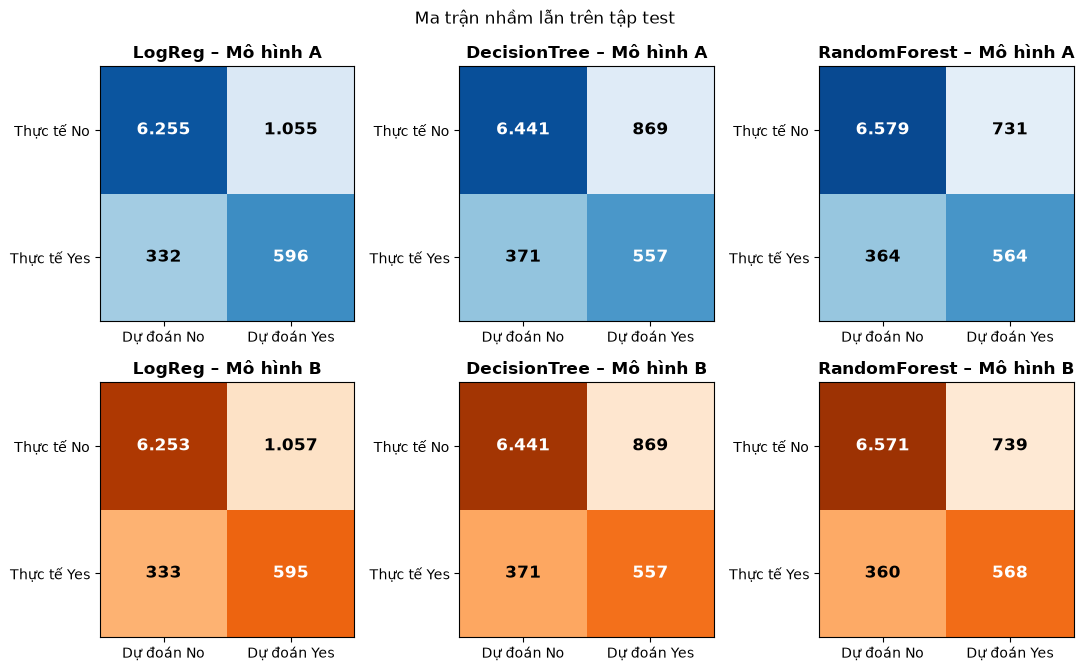

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6.8))
for i, s in enumerate('AB'):
    for j, m_name in enumerate(MODELS):
        ax = axes[i, j]
        cm = confusion_matrix(test.y, (proba[(m_name, s, 'test')] >= 0.5).astype(int))
        ax.imshow(cm / cm.sum(1, keepdims=True), cmap='Blues' if s == 'A' else 'Oranges', vmin=0, vmax=1)
        for (r, c), v in np.ndenumerate(cm):
            ax.text(c, r, f'{v:,}'.replace(',', '.'), ha='center', va='center', fontsize=12, fontweight='bold',
                    color='white' if cm[r, c] / cm[r].sum() > 0.6 else 'black')
        ax.set_xticks([0, 1]); ax.set_xticklabels(['Dự đoán No', 'Dự đoán Yes'])
        ax.set_yticks([0, 1]); ax.set_yticklabels(['Thực tế No', 'Thực tế Yes'])
        ax.set_title(f'{m_name} – Mô hình {s}', fontweight='bold')
fig.suptitle('Ma trận nhầm lẫn trên tập test', fontsize=12)
plt.tight_layout(); plt.savefig('Hinh_6_1_confusion.png', dpi=200); plt.show()

> **Nhận xét:** Random Forest tốt nhất trên tập test (F1 ≈ 0,507; PR-AUC ≈ 0,488, gấp khoảng 4,3 lần mức ngẫu nhiên 0,113). Kết quả Logistic Regression trên validation gần trùng với phương án 17 biến ở mục 3.4.

## 6.2. Mô hình B: cùng feature gốc + đúng 3 feature từ CAR
### 6.2.1. Thống kê 3 luật trên train / validation / test
Confidence của Rule_1 tính theo tỷ lệ **no** (vế phải của luật).

In [ ]:
rule_rows = []
for k in CAR:
    target = 0 if k == 'Rule_1' else 1
    for split, d in [('train', train), ('validation', val), ('test', test)]:
        m = d[k] == 1
        conf = (d.loc[m, 'y'] == target).mean()
        rule_rows.append({'Rule': k, 'Split': split, 'Số bản ghi': int(m.sum()), 'Coverage': m.mean(),
                          'Confidence': conf, 'Lift': conf / (d.y == target).mean()})
rule_stats = pd.DataFrame(rule_rows)
rule_stats

,Rule,Split,Số bản ghi,Coverage,Confidence,Lift
0,Rule_1,train,14766,0.5975,0.9510,1.0717
1,Rule_1,validation,5005,0.6076,0.9536,1.0747
2,Rule_1,test,4917,0.5969,0.9555,1.0768
3,Rule_2,train,416,0.0168,0.6731,5.9745
4,Rule_2,validation,137,0.0166,0.7445,6.6093
5,Rule_2,test,120,0.0146,0.7833,6.9538
6,Rule_3,train,479,0.0194,0.6054,5.3740
7,Rule_3,validation,154,0.0187,0.5390,4.7844
8,Rule_3,test,189,0.0229,0.6032,5.3545


In [ ]:
print('Giao nhau trên train:',
      {f'{a}&{b}': int(((train[a] == 1) & (train[b] == 1)).sum())
       for a, b in [('Rule_1', 'Rule_2'), ('Rule_1', 'Rule_3'), ('Rule_2', 'Rule_3')]})
print('Hai luật yes cùng phủ:', f"{((train.Rule_2 + train.Rule_3) > 0).mean():.2%} tập train")

Giao nhau trên train: {'Rule_1&Rule_2': 0, 'Rule_1&Rule_3': 0, 'Rule_2&Rule_3': 0}
Hai luật yes cùng phủ: 3.62% tập train


### 6.2.2. So sánh Mô hình A và Mô hình B trên tập test

In [ ]:
metrics = ['Precision', 'Recall', 'F1', 'PR-AUC']
cmp = results[results.Split == 'test'].set_index(['Model', 'Setting'])[metrics]
delta_test = cmp.xs('B', level='Setting') - cmp.xs('A', level='Setting')
display(cmp)
print('Chênh lệch B − A trên tập test:')
display(delta_test)

Precision  Recall     F1  PR-AUC
Model        Setting                                  
LogReg       A           0.3610  0.6422 0.4622  0.4614
             B           0.3602  0.6412 0.4612  0.4652
DecisionTree A           0.3906  0.6002 0.4732  0.4372
             B           0.3906  0.6002 0.4732  0.4398
RandomForest A           0.4355  0.6078 0.5074  0.4884
             B           0.4346  0.6121 0.5083  0.4901

Chênh lệch B − A trên tập test:


,Precision,Recall,F1,PR-AUC
Model,,,,
LogReg,-0.0008,-0.0011,-0.0010,0.0038
DecisionTree,0.0000,0.0000,0.0000,0.0026
RandomForest,-0.0009,0.0043,0.0009,0.0017


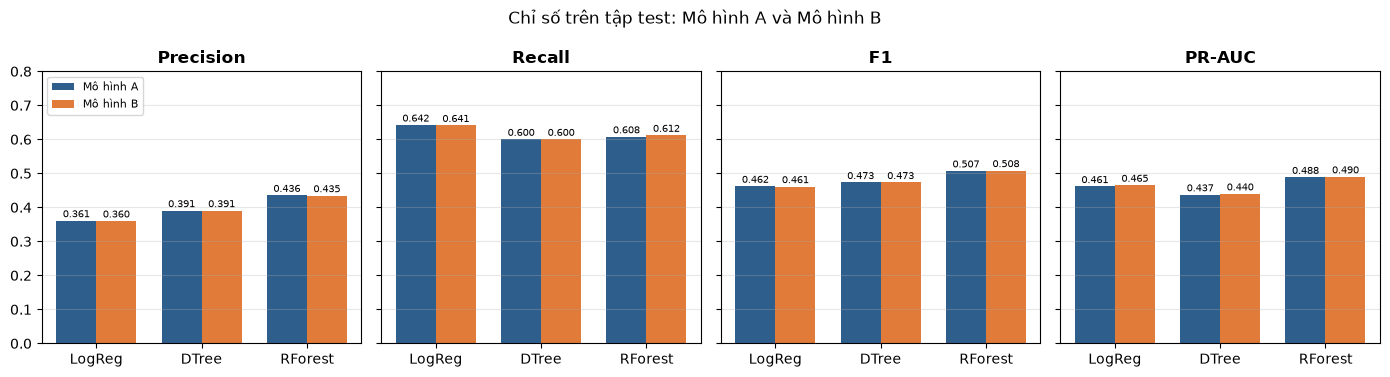

In [ ]:
x = np.arange(3); w = 0.38
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), sharey=True)
for ax, k in zip(axes, metrics):
    a = [cmp.loc[(m, 'A'), k] for m in MODELS]; b = [cmp.loc[(m, 'B'), k] for m in MODELS]
    r1 = ax.bar(x - w/2, a, w, color='#2E5E8C', label='Mô hình A')
    r2 = ax.bar(x + w/2, b, w, color='#E07B39', label='Mô hình B')
    for bars in (r1, r2):
        for r in bars:
            ax.text(r.get_x() + r.get_width()/2, r.get_height() + .01, f'{r.get_height():.3f}', ha='center', fontsize=7.5)
    ax.set_title(k, fontweight='bold'); ax.set_xticks(x); ax.set_xticklabels(['LogReg', 'DTree', 'RForest'])
    ax.set_ylim(0, .8); ax.grid(axis='y', alpha=.3)
axes[0].legend(fontsize=8, loc='upper left')
fig.suptitle('Chỉ số trên tập test: Mô hình A và Mô hình B', fontsize=12)
plt.tight_layout(); plt.savefig('Hinh_6_3_test_metrics.png', dpi=200); plt.show()

## 6.3. Lựa chọn mô hình
| Mô hình | Vai trò |
|---|---|
| Logistic Regression | Mô hình tuyến tính, không tự học tổ hợp điều kiện → kỳ vọng hưởng lợi nhiều nhất từ luật CAR |
| Decision Tree | Tự tìm ngưỡng và tổ hợp điều kiện; dễ trùng với luật |
| Random Forest | Ổn định, cho độ quan trọng đặc trưng |

Tham số được giữ cố định giữa A và B (xem ô 0.5).

In [ ]:
best = cmp.reset_index().sort_values('F1', ascending=False)
best[['Model', 'Setting'] + metrics]

,Model,Setting,Precision,Recall,F1,PR-AUC
5,RandomForest,B,0.4346,0.6121,0.5083,0.4901
4,RandomForest,A,0.4355,0.6078,0.5074,0.4884
3,DecisionTree,B,0.3906,0.6002,0.4732,0.4398
2,DecisionTree,A,0.3906,0.6002,0.4732,0.4372
0,LogReg,A,0.3610,0.6422,0.4622,0.4614
1,LogReg,B,0.3602,0.6412,0.4612,0.4652


## 6.4. So sánh công bằng và kiểm định
### 6.4.1. Chênh lệch B − A trên tập validation

In [ ]:
cmp_val = results[results.Split == 'val'].set_index(['Model', 'Setting'])[metrics]
delta_val = cmp_val.xs('B', level='Setting') - cmp_val.xs('A', level='Setting')
delta_val

,Precision,Recall,F1,PR-AUC
Model,,,,
LogReg,-0.0008,-0.0022,-0.0012,-0.0013
DecisionTree,0.0000,0.0000,0.0000,0.0063
RandomForest,0.0006,0.0032,0.0015,0.0004


### 6.4.2. Kiểm tra chéo phân tầng 5 lượt trên tập train
Nếu |Δ| nhỏ hơn độ lệch chuẩn giữa các lượt thì chênh lệch **không có ý nghĩa**. Ô này chạy khoảng 1–3 phút.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {'Precision': 'precision', 'Recall': 'recall', 'F1': 'f1', 'PR-AUC': 'average_precision'}
cv_rows = []
for m_name, model in MODELS.items():
    for s, (nums, feats) in SETTINGS.items():
        r = cross_validate(make_pipe(model, nums), train[feats], train.y, cv=cv, scoring=scoring, n_jobs=-1)
        row = {'Model': m_name, 'Setting': s}
        for k in scoring:
            row[f'{k}_mean'] = r[f'test_{k}'].mean(); row[f'{k}_std'] = r[f'test_{k}'].std()
        cv_rows.append(row)
cv_res = pd.DataFrame(cv_rows).set_index(['Model', 'Setting'])
cv_res

Precision_mean  Precision_std  Recall_mean  Recall_std  \
Model        Setting                                                           
LogReg       A                0.3456         0.0091       0.6232      0.0189   
             B                0.3461         0.0095       0.6221      0.0201   
DecisionTree A                0.3476         0.0299       0.6139      0.0148   
             B                0.3476         0.0299       0.6139      0.0148   
RandomForest A                0.4214         0.0105       0.5797      0.0239   
             B                0.4222         0.0113       0.5812      0.0233   

                      F1_mean  F1_std  PR-AUC_mean  PR-AUC_std  
Model        Setting                                            
LogReg       A         0.4446  0.0120       0.4361      0.0128  
             B         0.4447  0.0124       0.4391      0.0125  
DecisionTree A         0.4428  0.0221       0.4158      0.0102  
             B         0.4428  0.0221       0.4164      0.0097  
RandomForest A         0.4880  0.0154       0.4538      0.0084  
             B         0.4891  0.0156       0.4554      0.0072

In [ ]:
summary = pd.DataFrame({
    'ΔF1 val': delta_val['F1'], 'ΔF1 test': delta_test['F1'],
    'ΔF1 CV': cv_res.xs('B', level=1)['F1_mean'] - cv_res.xs('A', level=1)['F1_mean'],
    'std F1 CV': cv_res['F1_std'].groupby(level=0).max(),
    'ΔPR-AUC val': delta_val['PR-AUC'], 'ΔPR-AUC test': delta_test['PR-AUC'],
    'ΔPR-AUC CV': cv_res.xs('B', level=1)['PR-AUC_mean'] - cv_res.xs('A', level=1)['PR-AUC_mean'],
    'std PR-AUC CV': cv_res['PR-AUC_std'].groupby(level=0).max(),
})
summary['F1 có ý nghĩa?'] = summary['ΔF1 CV'].abs() > summary['std F1 CV']
summary['PR-AUC có ý nghĩa?'] = summary['ΔPR-AUC CV'].abs() > summary['std PR-AUC CV']
summary

,ΔF1 val,ΔF1 test,ΔF1 CV,std F1 CV,ΔPR-AUC val,ΔPR-AUC test,ΔPR-AUC CV,std PR-AUC CV,F1 có ý nghĩa?,PR-AUC có ý nghĩa?
Model,,,,,,,,,,
DecisionTree,0.0000,0.0000,0.0000,0.0221,0.0063,0.0026,0.0006,0.0102,False,False
LogReg,-0.0012,-0.0010,0.0001,0.0124,-0.0013,0.0038,0.0030,0.0128,False,False
RandomForest,0.0015,0.0009,0.0011,0.0156,0.0004,0.0017,0.0015,0.0084,False,False


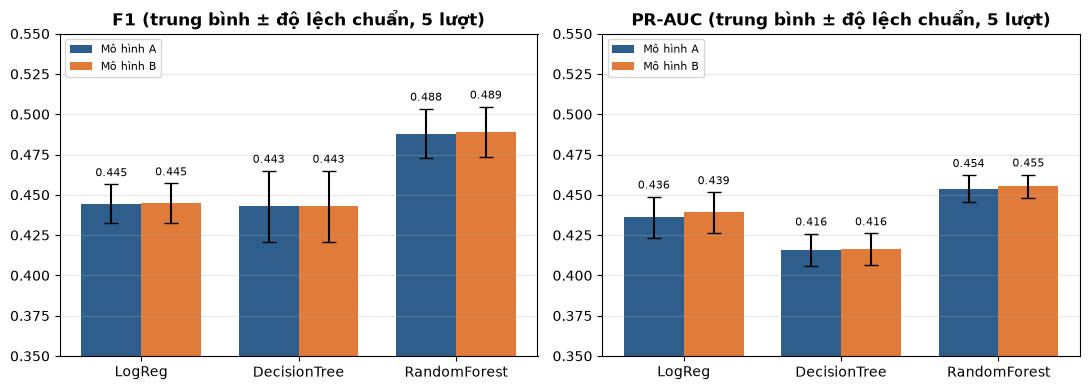

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, k in zip(axes, ['F1', 'PR-AUC']):
    for s, off, col in [('A', -w/2, '#2E5E8C'), ('B', w/2, '#E07B39')]:
        mu = [cv_res.loc[(m, s), f'{k}_mean'] for m in MODELS]; sd = [cv_res.loc[(m, s), f'{k}_std'] for m in MODELS]
        ax.bar(x + off, mu, w, yerr=sd, capsize=5, color=col, label=f'Mô hình {s}')
        for xi, a_, d_ in zip(x, mu, sd):
            ax.text(xi + off, a_ + d_ + .005, f'{a_:.3f}', ha='center', fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(list(MODELS)); ax.set_ylim(.35, .55); ax.grid(axis='y', alpha=.3)
    ax.legend(fontsize=8, loc='upper left'); ax.set_title(f'{k} (trung bình ± độ lệch chuẩn, 5 lượt)', fontweight='bold')
plt.tight_layout(); plt.savefig('Hinh_6_4_cv.png', dpi=200); plt.show()

### 6.4.3. Đường Precision-Recall trên tập test

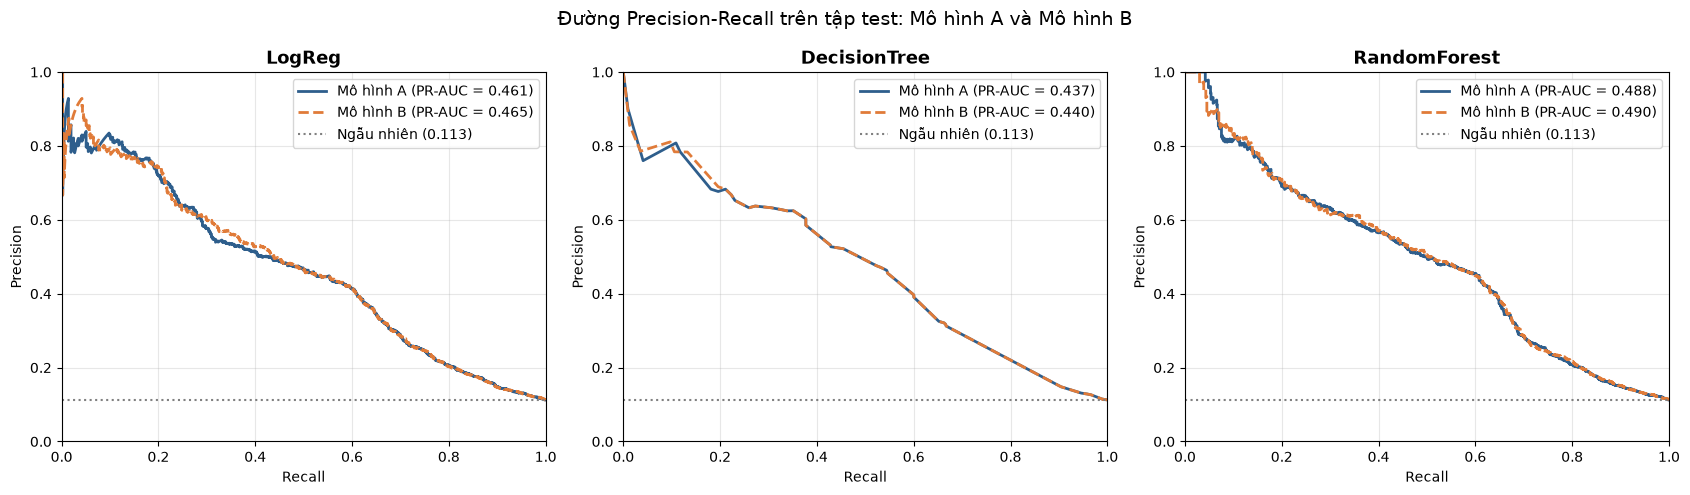

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, m_name in zip(axes, MODELS):
    for s, style, col in [('A', '-', '#2E5E8C'), ('B', '--', '#E07B39')]:
        p_ = proba[(m_name, s, 'test')]
        pr, rc, _ = precision_recall_curve(test.y, p_)
        ax.plot(rc, pr, style, lw=2, color=col, label=f'Mô hình {s} (PR-AUC = {average_precision_score(test.y, p_):.3f})')
    ax.axhline(test.y.mean(), color='gray', ls=':', label=f'Ngẫu nhiên ({test.y.mean():.3f})')
    ax.set_title(m_name, fontsize=13, fontweight='bold'); ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(alpha=.3); ax.legend(loc='upper right')
plt.suptitle('Đường Precision-Recall trên tập test: Mô hình A và Mô hình B', fontsize=14)
plt.tight_layout(); plt.savefig('Hinh_6_5_pr_curve.png', dpi=200); plt.show()

## 6.5. Giải thích: cải thiện, không cải thiện hay giảm hiệu quả
### 6.5.1. Luật so với một điều kiện đơn của biến gốc
Nếu luật đầy đủ chỉ nhỉnh hơn một điều kiện đơn, phần lớn thông tin đã có sẵn trong biến gốc.

In [ ]:
e = train.euribor3m
single = pd.DataFrame([
    ['Rule_1 (tỷ lệ no)', 'euribor3m > 3,1675', 1 - train.loc[e > 3.1675, 'y'].mean(), (train.loc[train.Rule_1 == 1, 'y'] == 0).mean()],
    ['Rule_2 (tỷ lệ yes)', 'poutcome = success', train.loc[train.poutcome == 'success', 'y'].mean(), train.loc[train.Rule_2 == 1, 'y'].mean()],
    ['Rule_3 (tỷ lệ yes)', 'euribor3m ≤ 0,7155', train.loc[e <= 0.7155, 'y'].mean(), train.loc[train.Rule_3 == 1, 'y'].mean()],
], columns=['Luật', 'Điều kiện đơn', 'Tỷ lệ với điều kiện đơn', 'Tỷ lệ với luật đầy đủ'])
display(single)
corr = train[CAR + ['euribor3m']].assign(poutcome_success=(train.poutcome == 'success').astype(int)).corr()
corr.loc[CAR, ['euribor3m', 'poutcome_success']]

,Luật,Điều kiện đơn,Tỷ lệ với điều kiện đơn,Tỷ lệ với luật đầy đủ
0,Rule_1 (tỷ lệ no),"euribor3m > 3,1675",0.9499,0.9510
1,Rule_2 (tỷ lệ yes),poutcome = success,0.6352,0.6731
2,Rule_3 (tỷ lệ yes),"euribor3m ≤ 0,7155",0.5641,0.6054


,euribor3m,poutcome_success
Rule_1,0.8377,-0.2214
Rule_2,-0.2075,0.6946
Rule_3,-0.2378,0.2429


### 6.5.2. Mô hình A đã dự đoán đúng hướng của luật chưa?
Tỷ lệ bản ghi được dự đoán **yes** trong từng nhóm luật (tập test) và số bản ghi đổi dự đoán khi thêm luật.

In [ ]:
rows = []
for m_name in MODELS:
    pa = proba[(m_name, 'A', 'test')] >= .5; pb = proba[(m_name, 'B', 'test')] >= .5
    for k in CAR + ['Ngoài 3 luật']:
        g = (test[CAR].sum(1) == 0).values if k == 'Ngoài 3 luật' else (test[k] == 1).values
        rows.append({'Model': m_name, 'Nhóm': k, 'Số bản ghi': int(g.sum()), 'Tỷ lệ yes thực tế': test.y.values[g].mean(),
                     'A dự đoán yes': pa[g].mean(), 'B dự đoán yes': pb[g].mean(), 'Số bản ghi đổi dự đoán': int((pa != pb)[g].sum())})
inside = pd.DataFrame(rows)
inside

,Model,Nhóm,Số bản ghi,Tỷ lệ yes thực tế,A dự đoán yes,B dự đoán yes,Số bản ghi đổi dự đoán
0,LogReg,Rule_1,4917,0.0445,0.0055,0.0055,0
1,LogReg,Rule_2,120,0.7833,1.0000,1.0000,0
2,LogReg,Rule_3,189,0.6032,1.0000,1.0000,0
3,LogReg,Ngoài 3 luật,3012,0.1663,0.4366,0.4369,19
4,DecisionTree,Rule_1,4917,0.0445,0.0020,0.0020,0
5,DecisionTree,Rule_2,120,0.7833,1.0000,1.0000,0
6,DecisionTree,Rule_3,189,0.6032,1.0000,1.0000,0
7,DecisionTree,Ngoài 3 luật,3012,0.1663,0.3675,0.3675,0
8,RandomForest,Rule_1,4917,0.0445,0.0073,0.0077,4
9,RandomForest,Rule_2,120,0.7833,1.0000,1.0000,0


### 6.5.3. Độ quan trọng (Random Forest) và hệ số (Logistic Regression)

In [ ]:
def rf_importance(s):
    pp = fitted[('RandomForest', s)]
    names = [n.split('__')[1] for n in pp.named_steps['pre'].get_feature_names_out()]
    return pd.Series(pp.named_steps['clf'].feature_importances_, index=names).sort_values(ascending=False)
imp_A, imp_B = rf_importance('A'), rf_importance('B')
print('Hạng của luật trong Random Forest B:', {k: f'{list(imp_B.index).index(k) + 1}/{len(imp_B)}' for k in CAR})
display(pd.DataFrame({'Importance A': imp_A, 'Importance B': imp_B}).loc[
    ['euribor3m', 'nr.employed', 'emp.var.rate', 'poutcome_success', 'contact_cellular'] + CAR])

def lr_coef(s):
    pp = fitted[('LogReg', s)]
    names = [n.split('__')[1] for n in pp.named_steps['pre'].get_feature_names_out()]
    return pd.Series(pp.named_steps['clf'].coef_[0], index=names)
pd.DataFrame({'Hệ số A': lr_coef('A'), 'Hệ số B': lr_coef('B')}).loc[
    ['euribor3m', 'nr.employed', 'poutcome_success', 'contact_cellular'] + CAR]

Hạng của luật trong Random Forest B: {'Rule_1': '5/59', 'Rule_2': '38/59', 'Rule_3': '39/59'}


,Importance A,Importance B
euribor3m,0.1580,0.1414
nr.employed,0.1114,0.0986
emp.var.rate,0.0754,0.0638
poutcome_success,0.0238,0.0222
contact_cellular,0.0152,0.0162
Rule_1,NaN,0.0550
Rule_2,NaN,0.0059
Rule_3,NaN,0.0058


,Hệ số A,Hệ số B
euribor3m,0.6685,0.9904
nr.employed,0.0430,-0.1703
poutcome_success,0.2019,0.2905
contact_cellular,0.2805,0.2334
Rule_1,NaN,-0.0335
Rule_2,NaN,-0.0338
Rule_3,NaN,0.1004


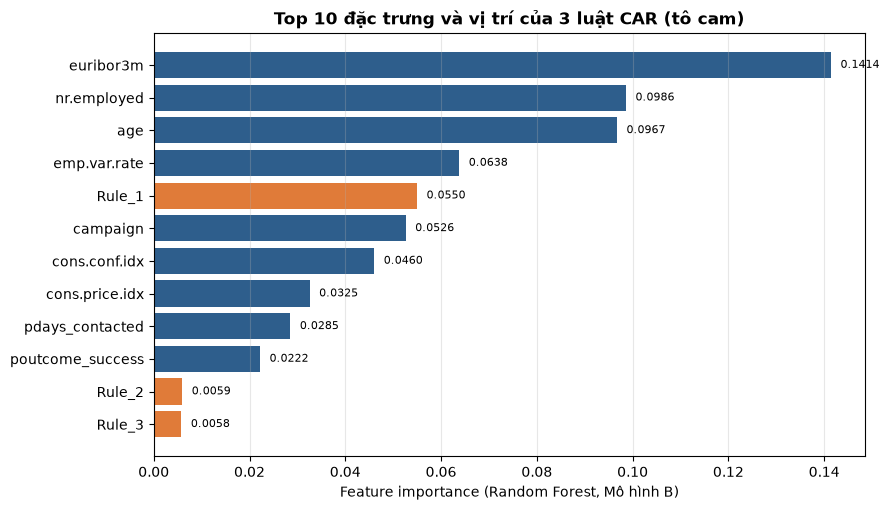

In [ ]:
top = imp_B.head(10)
extra = [k for k in CAR if k not in top.index]
plot = pd.concat([top, imp_B[extra]])
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(plot.index[::-1], plot.values[::-1], color=['#E07B39' if n in CAR else '#2E5E8C' for n in plot.index[::-1]])
for i, v in enumerate(plot.values[::-1]):
    ax.text(v + .002, i, f'{v:.4f}', va='center', fontsize=8)
ax.set_xlabel('Feature importance (Random Forest, Mô hình B)'); ax.grid(axis='x', alpha=.3)
ax.set_title('Top 10 đặc trưng và vị trí của 3 luật CAR (tô cam)', fontweight='bold')
plt.tight_layout(); plt.savefig('Hinh_6_8_importance.png', dpi=200); plt.show()

### 6.5.4. Decision Tree có dùng luật không? Logistic Regression có xếp hạng tốt hơn trong nhóm Rule_3 không?

In [ ]:
dt = fitted[('DecisionTree', 'B')]
names = [n.split('__')[1] for n in dt.named_steps['pre'].get_feature_names_out()]
used = [names[i] for i in dt.named_steps['clf'].tree_.feature if i >= 0]
print('Decision Tree B dùng luật ở:', {k: used.count(k) for k in CAR}, f'trên tổng {len(used)} điểm tách')

g = (test.Rule_3 == 1).values
for s in 'AB':
    ap = average_precision_score(test.y.values[g], proba[('LogReg', s, 'test')][g])
    print(f'Logistic Regression {s}: Average Precision trong nhóm Rule_3 = {ap:.4f}')

Decision Tree B dùng luật ở: {'Rule_1': 0, 'Rule_2': 0, 'Rule_3': 1} trên tổng 43 điểm tách
Logistic Regression A: Average Precision trong nhóm Rule_3 = 0.7285
Logistic Regression B: Average Precision trong nhóm Rule_3 = 0.7420


### Kết luận
- Thêm 3 đặc trưng CAR **không cải thiện có ý nghĩa**: mọi |Δ| nhỏ hơn độ lệch chuẩn giữa các lượt kiểm tra chéo (bảng `summary`). PR-AUC chỉ có xu hướng nhích nhẹ.
- Nguyên nhân: cả 3 luật đều dựa trên ngưỡng `euribor3m`, biến quan trọng nhất của mô hình gốc; Mô hình A đã dự đoán đúng hướng của luật trong các nhóm Rule_2/Rule_3; ảnh hưởng chỉ được chia lại giữa các cột cùng thông tin.
- Random Forest là mô hình phù hợp nhất. Giá trị chính của luật nằm ở **khả năng diễn giải** cho đội kinh doanh (Chương 7).

### Lưu kết quả

In [ ]:
results.to_csv('ket_qua_val_test.csv', index=False)
cv_res.to_csv('ket_qua_cross_validation.csv')
summary.to_csv('tong_hop_chenh_lech.csv')
rule_stats.to_csv('thong_ke_3_luat.csv', index=False)
inside.to_csv('du_doan_trong_nhom_luat.csv', index=False)
print('Đã lưu các bảng kết quả và hình Hinh_6_*.png')

Đã lưu các bảng kết quả và hình Hinh_6_*.png
